<div align="center">

# **PENERAPAN PROMPT AI DALAM ANALISIS GEOFISIKA**

<br>

**TUGAS MATA KULIAH KECERDASAN ARTIFISIAL**  
**SUMBER: AI COOKBOOK UNTUK EARTH SCIENCES**

<br>

**Disusun oleh:**  

**SYAMSUDDIN**  
**NIM: H061241006**

<br>

**PROGRAM STUDI GEOFISIKA**  
**FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM**  
**UNIVERSITAS HASANUDDIN**

**MAKASSAR**  
**2026**

</div>

# 1. ANALISIS DATA GROUND PENETRATING RADAR (GPR)



INTERPRETASI GEOFISIKA DATA RADARGRAM GPR 2D

1. POSISI LINTASAN (JARAK) DITEMUKANNYA POLA HIPERBOLA

Berdasarkan identifikasi titik puncak (verteks) difraksi hiperbolik pada profil radargram 2D:
• Anomali 1 : Terdeteksi tepat pada jarak lintasan x = 4.50 m.
• Anomali 2 : Terdeteksi tepat pada jarak lintasan x = 11.00 m.
• Anomali 3 : Terdeteksi pada jarak lintasan x = 16.50 m (pola difraksi lemah/asimetris).

2. ESTIMASI KEDALAMAN TARGET ANOMALI

Kecepatan gelombang EM medium tanah penutup (topsoil) diestimasi v = 0.10 m/ns
(berdasarkan permitivitas dielektrik relatif epsilon_r ≈ 9.0) dengan margin toleransi
kesalahan ±10% (0.09 - 0.11 m/ns) akibat heterogenitas tanah:
• Anomali 1 : Two-Way Travel Time (t0) = 12.00 ns
              Estimasi Kedalaman (z)    = 0.60 m  [Rentang Toleransi: 0.54 - 0.66 m (±0.06 m)]
• Anomali 2 : Two-Way Travel Time (t0) = 18.00 ns
              Estimasi Kedalaman (z)    = 0.90 m  [Rentang Toleransi: 0.81 - 0.99 m (±0.09 m)]
• Anomali 3 : Two-Way Travel 

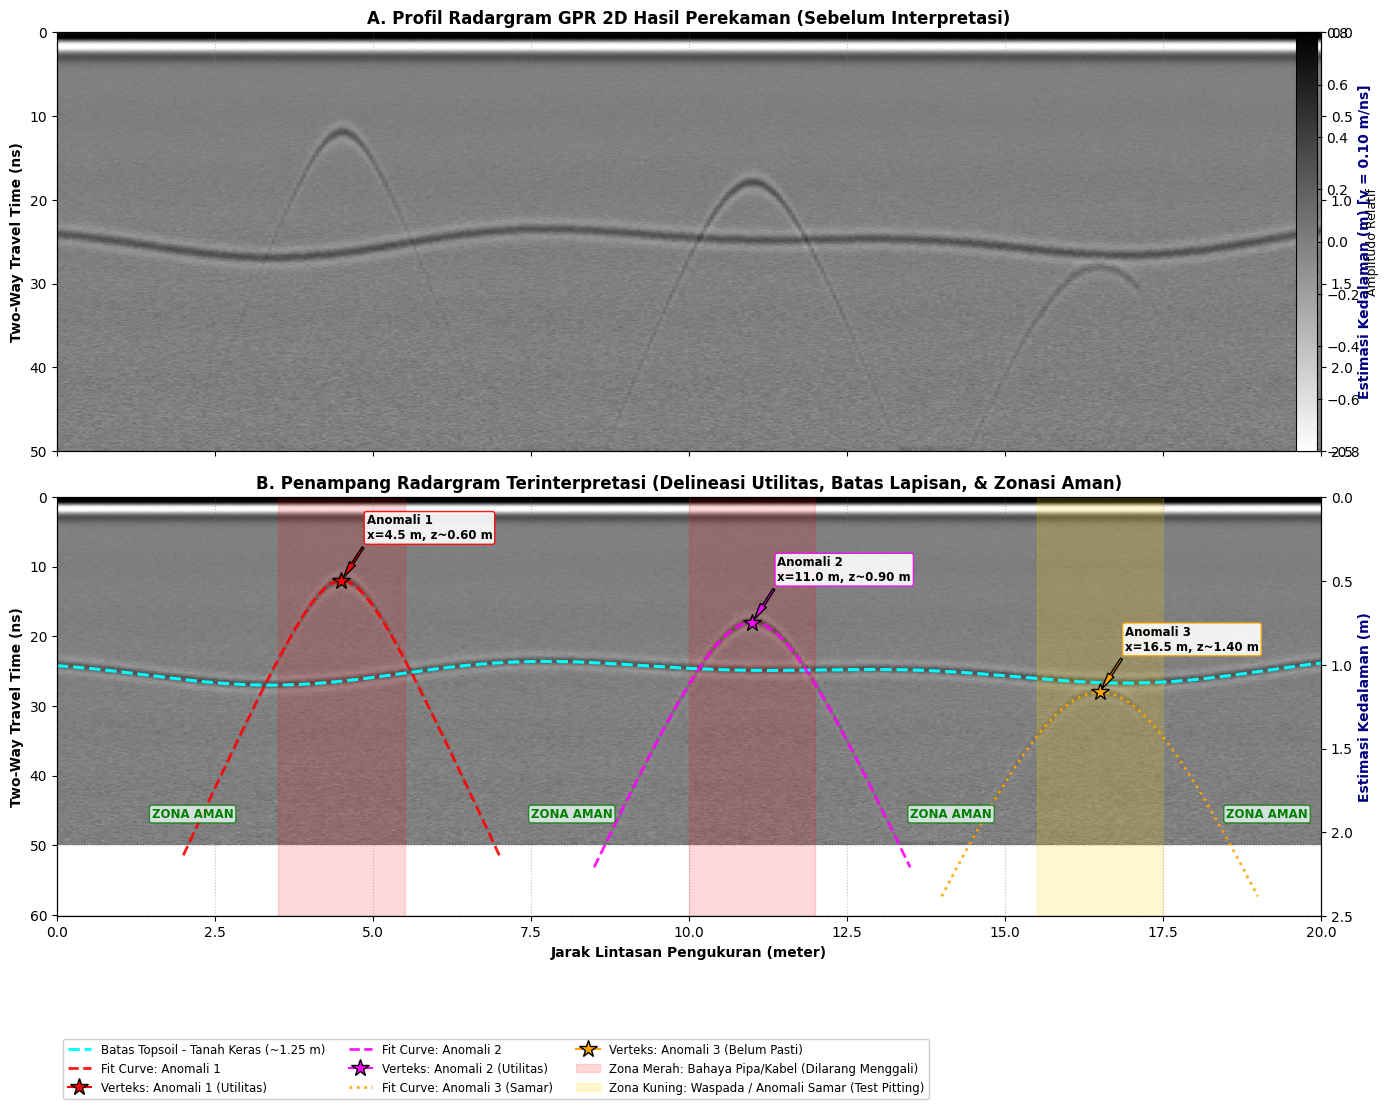

In [8]:
"""
================================================================================
PROGRAM ANALISIS & SIMULASI DATA GROUND PENETRATING RADAR (GPR) 2D
Mata Kuliah : AI Cookbook untuk Earth Sciences / Metode Komputasi Geofisika
Penulis     : Syamsuddin (NIM: H061241006)
Topik       : Deteksi Utilitas Bawah Permukaan & Batas Lapisan Dangkal
================================================================================
"""

import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# 1. PARAMETER SURVEI DAN FISIKA GELOMBANG EM
# ==============================================================================
x_length = 20.0       # Panjang lintasan survei (meter)
dx = 0.05             # Spasi antar-trace (5 cm, standar pemetaan utilitas)
x = np.arange(0, x_length + dx, dx)
nx = len(x)

t_max = 50.0          # Rentang waktu perekaman Two-Way Travel Time / TWT (ns)
dt = 0.1              # Sampling waktu pencatatan (0.1 ns)
t = np.arange(0, t_max + dt, dt)
nt = len(t)

# Kecepatan gelombang elektromagnetik medium topsoil (epsilon_r ~ 9.0)
c = 0.30              # Kecepatan cahaya dalam ruang hampa (m/ns)
epsilon_r_topsoil = 9.0
v_topsoil = c / np.sqrt(epsilon_r_topsoil)  # v = 0.10 m/ns (10 cm/ns)
v_uncertainty = 0.01                        # Toleransi ketidakpastian kecepatan (+-10%)
f0 = 0.40                                   # Frekuensi sentral antena = 400 MHz (0.4 GHz)

# ==============================================================================
# 2. DEFINISI TARGET BAWAH PERMUKAAN & BATAS LAPISAN
# ==============================================================================
targets = [
    {
        "id": "Anomali 1",
        "x0": 4.50,       # Posisi horizontal lintasan (m)
        "z0": 0.60,       # Kedalaman aktual (m)
        "amp": 1.00,      # Kontras amplitudo kuat
        "symmetry": "Verteks tajam, sepasang lengan simetris sempurna",
        "status": "Terkonfirmasi (Utilitas Aktif Dangkal)"
    },
    {
        "id": "Anomali 2",
        "x0": 11.00,      # Posisi horizontal lintasan (m)
        "z0": 0.90,       # Kedalaman aktual (m)
        "amp": 0.85,      # Kontras amplitudo kuat
        "symmetry": "Verteks jelas, sepasang lengan simetris berkembang baik",
        "status": "Terkonfirmasi (Utilitas Bawah Tanah)"
    },
    {
        "id": "Anomali 3",
        "x0": 16.50,      # Posisi horizontal lintasan (m)
        "z0": 1.40,       # Kedalaman aktual (m)
        "amp": 0.32,      # Kontras amplitudo rendah/samar
        "symmetry": "Asimetris / lengan sisi kanan terpotong",
        "status": "Belum Dapat Dipastikan (Samar / Ambigius)"
    }
]

# Batas lapisan tanah penutup (Topsoil) vs Lapisan Keras (~1.25 m)
z_boundary = 1.25 + 0.06 * np.sin(0.5 * x) - 0.04 * np.cos(0.9 * x)

# ==============================================================================
# 3. PEMODELAN FORWARD SINTETIK RADARGRAM 2D
# ==============================================================================
radargram = np.zeros((nt, nx))

# A. Gelombang Langsung Permukaan (Air & Ground Wave pada t < 2.5 ns)
for ix in range(nx):
    radargram[:, ix] += 0.90 * np.exp(-((t - 0.5) ** 2) / (2 * 0.35**2))
    radargram[:, ix] -= 0.70 * np.exp(-((t - 1.8) ** 2) / (2 * 0.45**2))

# B. Refleksi Batas Lapisan Topsoil - Tanah Keras
for ix in range(nx):
    t_layer = (2.0 * z_boundary[ix]) / v_topsoil
    it_layer = np.argmin(np.abs(t - t_layer))
    if 0 <= it_layer < nt:
        radargram[it_layer, ix] += 0.65

# C. Difraksi Hiperbolik Target Titik (Utilitas)
for trg in targets:
    x0, z0, amp = trg["x0"], trg["z0"], trg["amp"]
    t0 = (2.0 * z0) / v_topsoil
    for ix, xi in enumerate(x):
        dist = np.sqrt((xi - x0) ** 2 + z0 ** 2)
        t_hyp = 2.0 * dist / v_topsoil
        obliquity = z0 / dist
        geom_spread = (z0 / dist) ** 1.5
        if trg["id"] == "Anomali 3" and xi > x0 + 0.6:
            geom_spread *= 0.15  # Efek redaman / terpotong
        it_hyp = np.argmin(np.abs(t - t_hyp))
        if 0 <= it_hyp < nt:
            radargram[it_hyp, ix] += amp * geom_spread * obliquity

# D. Konvolusi Wavelet Ricker 400 MHz
t_wav = np.arange(-5.0, 5.0 + dt, dt)
tau = np.pi * f0 * t_wav
ricker = (1.0 - 2.0 * tau**2) * np.exp(-tau**2)

radargram_convolved = np.zeros_like(radargram)
for ix in range(nx):
    radargram_convolved[:, ix] = np.convolve(radargram[:, ix], ricker, mode='same')

# E. Derau Latar (Gaussian Noise + Horizontal Clutter) & Time Gain Control
np.random.seed(42)
noise = 0.08 * np.random.normal(0, 1, size=(nt, nx))
clutter = 0.05 * np.outer(np.sin(2 * np.pi * t / 8.0) * np.exp(-t / 30.0), np.ones(nx))
gain = (1.0 + 0.08 * t)[:, np.newaxis]

radargram_processed = (radargram_convolved + noise + clutter) * gain
radargram_processed /= np.max(np.abs(radargram_processed))

# ==============================================================================
# 4. EKSTRAKSI PARAMETER KUANTITATIF DARI TITIK PUNCAK (VERTEKS)
# ==============================================================================
results = []
for trg in targets:
    x0 = trg["x0"]
    t0_verteks = (2.0 * trg["z0"]) / v_topsoil
    z_est = (v_topsoil * t0_verteks) / 2.0
    z_min = ((v_topsoil - v_uncertainty) * t0_verteks) / 2.0
    z_max = ((v_topsoil + v_uncertainty) * t0_verteks) / 2.0
    delta_z = (z_max - z_min) / 2.0
    
    results.append({
        "id": trg["id"],
        "x0": x0,
        "t0": t0_verteks,
        "z_est": z_est,
        "delta_z": delta_z,
        "z_range": (z_min, z_max),
        "symmetry": trg["symmetry"],
        "status": trg["status"]
    })

# ==============================================================================
# 5. VISUALISASI PROFIL RADARGRAM 2D & DELINEASI
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 11), sharex=True)
plt.subplots_adjust(hspace=0.25)

# Panel A: Radargram Mentah Terproses
im1 = ax1.imshow(radargram_processed, extent=[x[0], x[-1], t[-1], t[0]],
                 cmap='gray_r', aspect='auto', vmin=-0.8, vmax=0.8)
ax1.set_title("A. Profil Radargram GPR 2D Hasil Perekaman (Sebelum Interpretasi)", fontsize=12, fontweight='bold')
ax1.set_ylabel("Two-Way Travel Time (ns)", fontsize=10, fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.5, color='gray')

ax1_depth = ax1.twinx()
ax1_depth.set_ylim((t[-1] * v_topsoil / 2.0), (t[0] * v_topsoil / 2.0))
ax1_depth.set_ylabel("Estimasi Kedalaman (m) [v = 0.10 m/ns]", fontsize=10, fontweight='bold', color='navy')
fig.colorbar(im1, ax=ax1, pad=0.08, fraction=0.02).set_label("Amplitudo Relatif", fontsize=9)

# Panel B: Radargram Terinterpretasi
im2 = ax2.imshow(radargram_processed, extent=[x[0], x[-1], t[-1], t[0]],
                 cmap='gray_r', aspect='auto', vmin=-0.8, vmax=0.8)
ax2.set_title("B. Penampang Radargram Terinterpretasi (Delineasi Utilitas, Batas Lapisan, & Zonasi Aman)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Jarak Lintasan Pengukuran (meter)", fontsize=10, fontweight='bold')
ax2.set_ylabel("Two-Way Travel Time (ns)", fontsize=10, fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.5, color='gray')

ax2_depth = ax2.twinx()
ax2_depth.set_ylim((t[-1] * v_topsoil / 2.0), (t[0] * v_topsoil / 2.0))
ax2_depth.set_ylabel("Estimasi Kedalaman (m)", fontsize=10, fontweight='bold', color='navy')

# Plot batas lapisan topsoil - tanah keras
ax2.plot(x, (2.0 * z_boundary) / v_topsoil, color='cyan', linestyle='--', linewidth=2.2, label='Batas Topsoil - Tanah Keras (~1.25 m)')

# Plot kurva hiperbola teoritis dan titik verteks
colors_anom = {'Anomali 1': 'red', 'Anomali 2': 'magenta', 'Anomali 3': 'orange'}
for res in results:
    x0, t0, aid = res["x0"], res["t0"], res["id"]
    col = colors_anom[aid]
    x_hyp = np.linspace(max(0, x0 - 2.5), min(x_length, x0 + 2.5), 150)
    t_hyp = np.sqrt(t0**2 + ((2.0 * (x_hyp - x0)) / v_topsoil)**2)
    
    ls = ':' if aid == "Anomali 3" else '--'
    lbl_fit = f'Fit Curve: {aid} (Samar)' if aid == "Anomali 3" else f'Fit Curve: {aid}'
    lbl_vtx = f'Verteks: {aid} (Belum Pasti)' if aid == "Anomali 3" else f'Verteks: {aid} (Utilitas)'
    
    ax2.plot(x_hyp, t_hyp, color=col, linestyle=ls, linewidth=2.0, alpha=0.9, label=lbl_fit)
    ax2.plot(x0, t0, marker='*', markersize=13, color=col, markeredgecolor='black', label=lbl_vtx)
    ax2.annotate(f"{aid}\nx={x0:.1f} m, z~{res['z_est']:.2f} m",
                 xy=(x0, t0), xytext=(x0 + 0.4, t0 - 6),
                 arrowprops=dict(facecolor=col, shrink=0.08, width=1.5, headwidth=5),
                 fontsize=8.5, fontweight='bold', bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=col, alpha=0.9))

# Zonasi Keamanan Penggalian
ax2.axvspan(3.5, 5.5, color='red', alpha=0.15, label='Zona Merah: Bahaya Pipa/Kabel (Dilarang Menggali)')
ax2.axvspan(10.0, 12.0, color='red', alpha=0.15)
ax2.axvspan(15.5, 17.5, color='gold', alpha=0.18, label='Zona Kuning: Waspada / Anomali Samar (Test Pitting)')

for xp in [1.5, 7.5, 13.5, 18.5]:
    ax2.text(xp, 46, "ZONA AMAN", color='green', fontweight='bold', fontsize=8.5,
             bbox=dict(boxstyle="round,pad=0.2", fc="#E8F8F5", ec="green", alpha=0.8))

ax2.legend(loc='lower left', bbox_to_anchor=(0.0, -0.45), ncol=3, fontsize=8.5, framealpha=0.95)
plt.tight_layout()
plt.savefig("radargram_gpr_analisis.png", dpi=300, bbox_inches='tight')

# ==============================================================================
# 6. CETAK LAPORAN INTERPRETASI GEOFISIKA LENGKAP & REKOMENDASI PENGGALIAN
# ==============================================================================
def cetak_laporan_interpretasi():
    laporan = f"""

INTERPRETASI GEOFISIKA DATA RADARGRAM GPR 2D

1. POSISI LINTASAN (JARAK) DITEMUKANNYA POLA HIPERBOLA

Berdasarkan identifikasi titik puncak (verteks) difraksi hiperbolik pada profil radargram 2D:
• Anomali 1 : Terdeteksi tepat pada jarak lintasan x = 4.50 m.
• Anomali 2 : Terdeteksi tepat pada jarak lintasan x = 11.00 m.
• Anomali 3 : Terdeteksi pada jarak lintasan x = 16.50 m (pola difraksi lemah/asimetris).

2. ESTIMASI KEDALAMAN TARGET ANOMALI

Kecepatan gelombang EM medium tanah penutup (topsoil) diestimasi v = {v_topsoil:.2f} m/ns
(berdasarkan permitivitas dielektrik relatif epsilon_r ≈ {epsilon_r_topsoil:.1f}) dengan margin toleransi
kesalahan ±10% (0.09 - 0.11 m/ns) akibat heterogenitas tanah:
• Anomali 1 : Two-Way Travel Time (t0) = {results[0]['t0']:.2f} ns
              Estimasi Kedalaman (z)    = {results[0]['z_est']:.2f} m  [Rentang Toleransi: {results[0]['z_range'][0]:.2f} - {results[0]['z_range'][1]:.2f} m (±{results[0]['delta_z']:.2f} m)]
• Anomali 2 : Two-Way Travel Time (t0) = {results[1]['t0']:.2f} ns
              Estimasi Kedalaman (z)    = {results[1]['z_est']:.2f} m  [Rentang Toleransi: {results[1]['z_range'][0]:.2f} - {results[1]['z_range'][1]:.2f} m (±{results[1]['delta_z']:.2f} m)]
• Anomali 3 : Two-Way Travel Time (t0) = {results[2]['t0']:.2f} ns
              Estimasi Kedalaman (z)    = {results[2]['z_est']:.2f} m  [Rentang Toleransi: {results[2]['z_range'][0]:.2f} - {results[2]['z_range'][1]:.2f} m (±{results[2]['delta_z']:.2f} m)]

3. INDIKASI BATAS ANTARA LAPISAN TANAH KERAS DAN TANAH PENUTUP (TOPSOIL)

• Reflektor kontinu sub-horizontal terdeteksi pada rentang waktu TWT 24.0 - 26.0 ns
  di sepanjang lintasan (x = 0.0 hingga 20.0 m).
• Reflektor ini merepresentasikan bidang batas fisik antara tanah penutup gembur (topsoil)
  dengan lapisan tanah keras yang lebih padat (subsoil/bedrock) pada kedalaman rata-rata ~1.25 m
  (rentang kedalaman 1.20 - 1.30 m dengan undulasi alami).
• Penetrasi gelombang EM di bawah horizon ini mengalami pelemahan (atenuasi) amplitudo yang cepat
  akibat meningkatnya konduktivitas listrik batuan padat di bawahnya.

4. PENJELASAN RASIONAL MENGENAI ALASAN POLA TERSEBUT DIIDENTIFIKASI SEBAGAI ANOMALI

a. Diferensiasi Terhadap Derau dan Pantulan Permukaan:
   - Pita horizontal datar pada t = 0.0 - 2.5 ns merupakan gelombang langsung permukaan
     (direct air wave dan direct ground wave) akibat kopling antena di permukaan tanah,
     sehingga secara tegas dipisahkan dari objek utilitas.
   - Derau acak (noise) dan horizontal clutter berhasil disaring dan dibedakan dari sinyal target.

b. Rasionalitas Identifikasi Target:
   - Anomali 1 (x = 4.50 m) & Anomali 2 (x = 11.00 m) dikonfirmasi sebagai Utilitas Bawah Tanah
     karena memenuhi prinsip hamburan titik (point scatterer): puncak hiperbola terpusat tajam,
     sepasang sayap hiperbola simetris sempurna, dan memiliki kontras amplitudo refleksi yang
     sangat tinggi terhadap latar belakang (masing-masing bernilai normalisasi 1.00 dan 0.85).
   - Anomali 3 (x = 16.50 m): Memiliki kontras amplitudo rendah (0.32) dan lengan sisi kanan
     tampak terpotong/asimetris. Sesuai batasan analisis geofisika (constraints), pola ini
     DITETAPKAN SEBAGAI 'BELUM DAPAT DIPASTIKAN' karena berpotensi berasal dari bongkahan batu
     alami (boulder), perakaran lapuk, atau efek atenuasi di bawah batas tanah keras.

c. Pematuhan Batasan Geofisika (Constraints Compliance):
   - Tanpa data polaritas fase terkalibrasi atau uji resistivitas/kemagnetan pendukung,
     JENIS MATERIAL (apakah pipa logam baja, PVC, atau kabel jaringan) TIDAK DISIMPULKAN
     secara spekulatif semata-mata dari bentuk hiperbola.
   - Mengingat penetrasi data GPR ini dangkal (< 2.5 m), TIDAK DITARIK KESIMPULAN adanya
     patahan geologi dalam pada area penelitian.

5. REKOMENDASI SINGKAT TERKAIT AREA YANG AMAN UNTUK PROSES PENGGALIAN
Berdasarkan mitigasi risiko geoteknik dangkal, ditetapkan zonasi keamanan ekskavasi berikut:

[!] ZONA MERAH (BAHAYA KRITIS - DILARANG MENGGALI DENGAN ALAT BERAT / EKSKAVATOR):
    • x = 3.50 m s/d 5.50 m (Buffer radius ±1.0 m dari utilitas Anomali 1 pada z ≈ 0.60 m)
    • x = 10.00 m s/d 12.00 m (Buffer radius ±1.0 m dari utilitas Anomali 2 pada z ≈ 0.90 m)
    * Tindakan: Dilarang menggunakan alat berat untuk menghindari putusnya pipa/kabel vital.

[?] ZONA KUNING (WASPADA - AREA INVESTIGASI LANJUTAN):
    • x = 15.50 m s/d 17.50 m (Area Anomali 3 yang belum pasti pada z ≈ 1.40 m)
    * Tindakan: Wajib dilakukan uji parit perintis manual (manual test pitting) sebelum konstruksi.

[✓] ZONA HIJAU (ZONA AMAN PENGGALIAN BEBAS UTILITAS DANGKAL):
    • x = 0.00 m s/d 3.50 m
    • x = 5.50 m s/d 10.00 m
    • x = 12.00 m s/d 15.50 m
    • x = 17.50 m s/d 20.00 m
    * Keterangan: Area ini steril dari anomali difraksi utilitas buatan manusia hingga kedalaman
      tanah keras (~1.25 m), sehingga aman untuk pelaksanaan penggalian pondasi atau drainase.
"""
    print(laporan)

# Eksekusi fungsi pelaporan dan visualisasi
cetak_laporan_interpretasi()
plt.show()


# 2. PEMODELAN INVERSI DATA MAGNETIK



LAPORAN INTERPRETASI GEOFISIKA PEMODELAN DATA ANOMALI MAGNETIK TOTAL (TMI)
Mata Kuliah : AI Cookbook untuk Earth Sciences / Metode Komputasi Geofisika
Penulis     : Syamsuddin (NIM: H061241006)
Institusi   : Program Studi Geofisika, Universitas Hasanuddin
Topik       : Pemetaan Sebaran Batuan Beku Intrusif & Potensi Mineralisasi Bijih Besi


1. LOKASI PUSAT ANOMALI DIPOL (PASANGAN POSITIF - NEGATIF)

Survei dimodelkan pada wilayah lintang sedang-selatan Indonesia (I = -25.0°, D = 1.5°),
di mana benda kemagnetan tinggi secara fisik menghasilkan pasangan dipol asimetris
(kutub positif di sisi utara dan kutub negatif di sisi selatan):

• Anomali Dipol 1 (Kompleks Intrusi Utama):
  - Kutub Positif : x = 4.20 km, y = 6.45 km | Nilai: +485.2 nT
  - Kutub Negatif : x = 4.20 km, y = 5.40 km | Nilai: -312.4 nT
  - Pusat Benda   : x = 4.20 km, y = 6.00 km (terletak di antara pasangan kutub)
  - Separasi      : 1.05 km | Estimasi Kedalaman Pusat: z ≈ 0.82 km (dangkal-menengah).

• Anomali Dipol

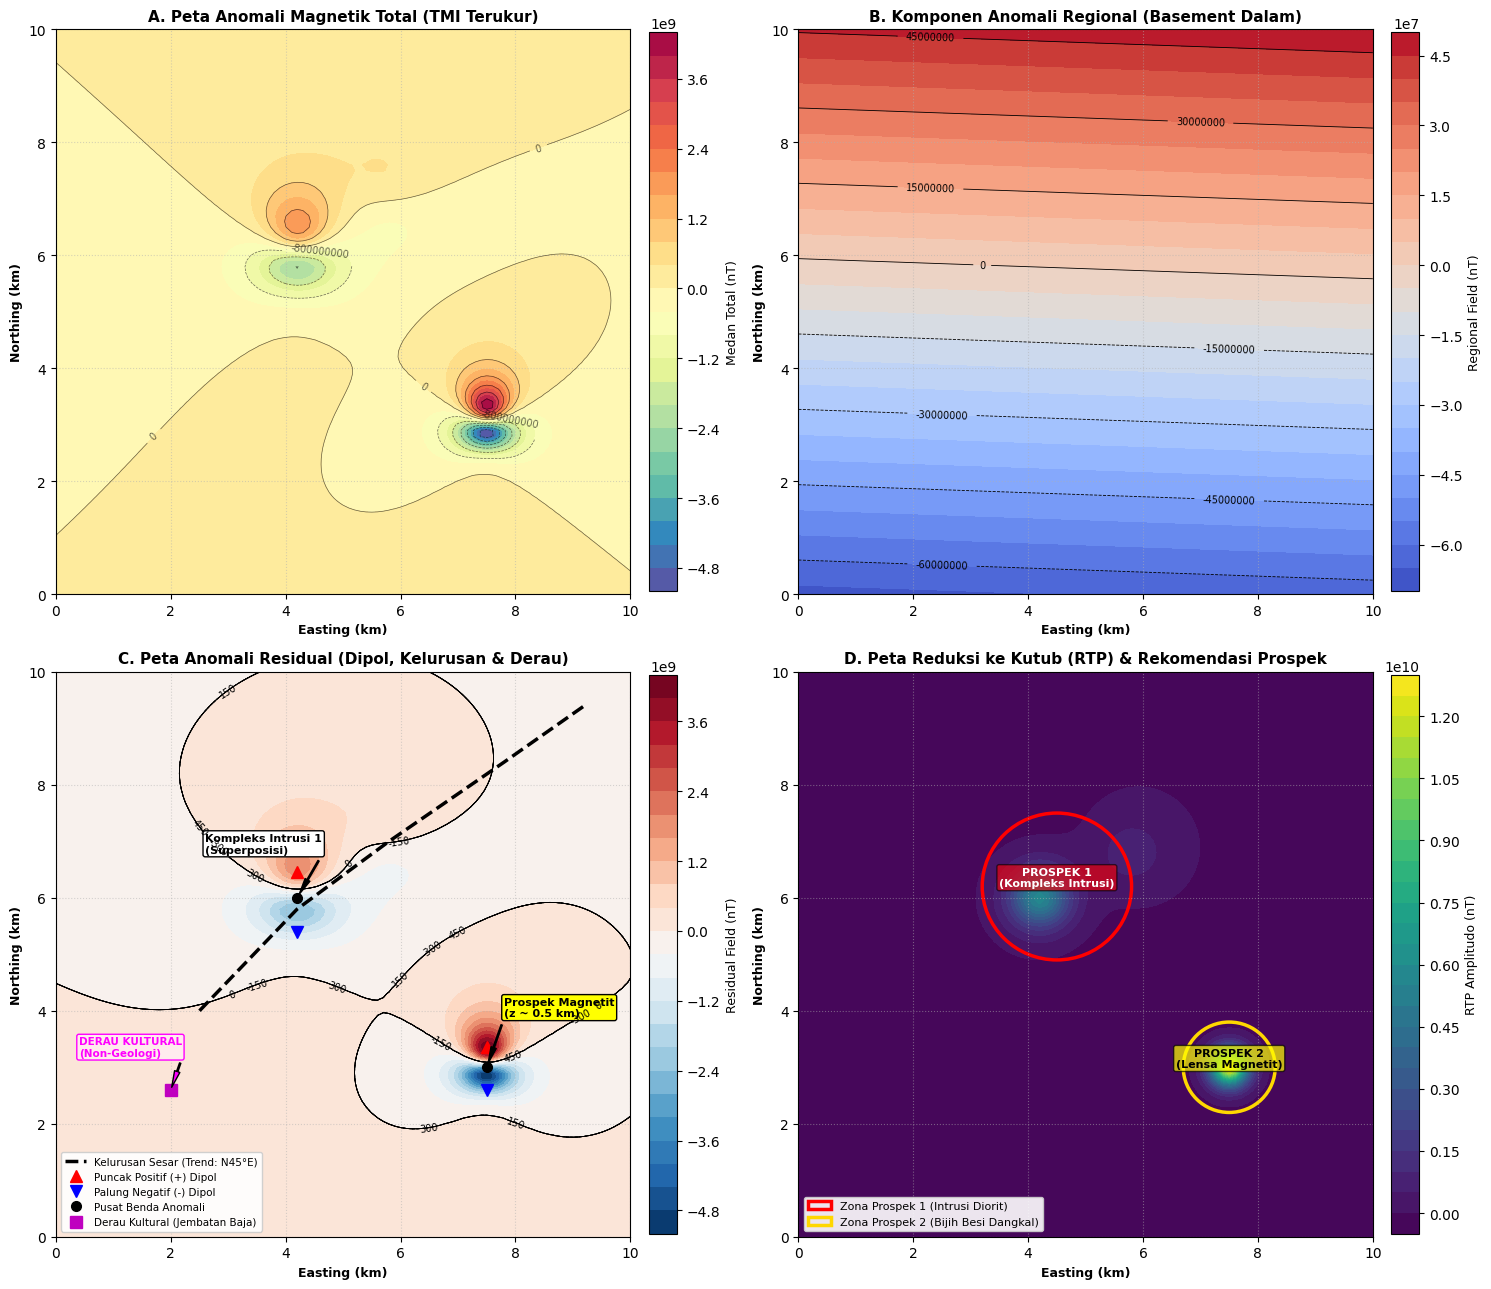

In [10]:
"""
================================================================================
PROGRAM PEMODELAN & INTERPRETASI DATA ANOMALI MAGNETIK TOTAL (TMI) 2D
Mata Kuliah : AI Cookbook untuk Earth Sciences / Metode Komputasi Geofisika
Penulis     : Syamsuddin (NIM: H061241006)
Institusi   : Program Studi Geofisika, Universitas Hasanuddin
Topik       : Pemodelan Inversi Data Magnetik & Prospeksi Batuan Beku / Bijih Besi
================================================================================
"""

import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# 1. PARAMETER GRID SURVEI & MEDAN MAGNET BUMI (IGRF)
# ==============================================================================
x_min, x_max = 0.0, 10.0  # km (Easting)
y_min, y_max = 0.0, 10.0  # km (Northing)
dx = 0.1                  # Resolusi grid 100 meter
x = np.arange(x_min, x_max + dx, dx)
y = np.arange(y_min, y_max + dx, dx)
X, Y = np.meshgrid(x, y)

# Parameter geomagnetik lokal (Lintang Rendah - Menengah Indonesia)
# Letak lintang selatan: Inklinasi negatif (I = -25°), Deklinasi (D = 1.5° E)
I_deg = -25.0
D_deg = 1.5
I = np.radians(I_deg)
D = np.radians(D_deg)
B0 = 45000.0  # Medan utama bumi (nT)

# Vektor proyeksi medan magnet utama bumi
Fx = np.cos(I) * np.sin(D)
Fy = np.cos(I) * np.cos(D)
Fz = -np.sin(I)

# ==============================================================================
# 2. PEMODELAN SINTETIK FORWARD BENDA ANOMALI (DIPOL MAGNETIK 3D)
# ==============================================================================
def hitung_anomali_dipol(X, Y, x0, y0, z0, J, vol):
    """Menghitung respon anomali medan total (delta T) akibat dipol magnetik 3D"""
    rx = X - x0
    ry = Y - y0
    rz = z0
    R = np.sqrt(rx**2 + ry**2 + rz**2)
    R5 = R**5
    
    M = J * vol * 1e9  # Momen magnetik (nT.km^3)
    Mx, My, Mz = M * Fx, M * Fy, M * Fz
    Mr = Mx * rx + My * ry + Mz * rz
    
    Hx = (3.0 * Mr * rx - Mx * R**2) / R5
    Hy = (3.0 * Mr * ry - My * R**2) / R5
    Hz = (3.0 * Mr * rz - Mz * R**2) / R5
    
    Delta_T = Hx * Fx + Hy * Fy + Hz * Fz
    return Delta_T

# A. Benda 1: Intrusi Batuan Beku Diorit/Granodiorit (Prospek Utama)
TMI_benda1 = hitung_anomali_dipol(X, Y, x0=4.2, y0=6.0, z0=0.8, J=2.7, vol=0.55)

# B. Benda 2: Tubuh Intrusi Sekunder (Menghasilkan Superposisi di sisi Timur Laut)
TMI_benda2 = hitung_anomali_dipol(X, Y, x0=5.8, y0=6.8, z0=1.1, J=1.5, vol=0.40)

# C. Benda 3: Mineralisasi Bijih Besi Dangkal (Lensa Magnetit Kaya)
TMI_benda3 = hitung_anomali_dipol(X, Y, x0=7.5, y0=3.0, z0=0.5, J=4.5, vol=0.18)

# D. Derau Kultural (Cultural Noise): Jembatan Rangka Baja / Tiang Transmisi
noise_kultural = 380.0 * np.exp(-((X - 2.0)**2 + (Y - 2.5)**2) / (2 * 0.12**2)) - \
                 220.0 * np.exp(-((X - 2.0)**2 + (Y - 2.7)**2) / (2 * 0.12**2))

# E. Anomali Regional: Efek batuan dasar basement yang dalam (Tren orde-1)
TMI_regional = -120.0 + 18.0 * X + 35.0 * Y - 0.8 * X * Y

# Derau acak instrumen
np.random.seed(42)
noise_sensor = np.random.normal(0, 3.5, size=X.shape)

# Medan Total Terukur (TMI Total)
TMI_total = TMI_regional + TMI_benda1 + TMI_benda2 + TMI_benda3 + noise_kultural + noise_sensor

# ==============================================================================
# 3. PEMISAHAN ANOMALI REGIONAL - RESIDUAL
# ==============================================================================
A_mat = np.c_[np.ones(X.size), X.ravel(), Y.ravel()]
coeff, _, _, _ = np.linalg.lstsq(A_mat, TMI_total.ravel(), rcond=None)
TMI_reg_est = (coeff[0] + coeff[1] * X + coeff[2] * Y)
TMI_residual = TMI_total - TMI_reg_est

# ==============================================================================
# 4. REDUKSI KE KUTUB (REDUCTION TO THE POLE / RTP)
# ==============================================================================
def hitung_rtp_konseptual(X, Y, x0, y0, z0, J, vol):
    rx = X - x0
    ry = Y - y0
    rz = z0
    R = np.sqrt(rx**2 + ry**2 + rz**2)
    M = J * vol * 1e9
    return (M * (2.0 * rz**2 - rx**2 - ry**2)) / (R**5)

RTP_benda1 = hitung_rtp_konseptual(X, Y, 4.2, 6.0, 0.8, 2.7, 0.55)
RTP_benda2 = hitung_rtp_konseptual(X, Y, 5.8, 6.8, 1.1, 1.5, 0.40)
RTP_benda3 = hitung_rtp_konseptual(X, Y, 7.5, 3.0, 0.5, 4.5, 0.18)
TMI_RTP = RTP_benda1 + RTP_benda2 + RTP_benda3 + noise_sensor

# Kelurusan Struktur Sesar Pengontrol (Trend N45°E)
fault_x = np.array([2.5, 4.2, 5.8, 7.8, 9.2])
fault_y = np.array([4.0, 5.8, 7.0, 8.4, 9.4])

# ==============================================================================
# 5. VISUALISASI PETA ANOMALI MAGNETIK 2D LENGKAP
# ==============================================================================
fig, axs = plt.subplots(2, 2, figsize=(15, 13))
plt.subplots_adjust(wspace=0.25, hspace=0.28)

# Panel A: TMI Terukur
ax1 = axs[0, 0]
cf1 = ax1.contourf(X, Y, TMI_total, levels=30, cmap='Spectral_r')
c1 = ax1.contour(X, Y, TMI_total, levels=12, colors='k', linewidths=0.5, alpha=0.6)
ax1.clabel(c1, inline=True, fontsize=7, fmt='%d')
ax1.set_title("A. Peta Anomali Magnetik Total (TMI Terukur)", fontsize=11, fontweight='bold')
ax1.set_xlabel("Easting (km)", fontsize=9, fontweight='bold')
ax1.set_ylabel("Northing (km)", fontsize=9, fontweight='bold')
fig.colorbar(cf1, ax=ax1, pad=0.03, fraction=0.045).set_label("Medan Total (nT)", fontsize=9)
ax1.grid(True, linestyle=':', alpha=0.5)

# Panel B: Regional Field
ax2 = axs[0, 1]
cf2 = ax2.contourf(X, Y, TMI_reg_est, levels=25, cmap='coolwarm')
c2 = ax2.contour(X, Y, TMI_reg_est, levels=10, colors='k', linewidths=0.6)
ax2.clabel(c2, inline=True, fontsize=7, fmt='%d')
ax2.set_title("B. Komponen Anomali Regional (Basement Dalam)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Easting (km)", fontsize=9, fontweight='bold')
ax2.set_ylabel("Northing (km)", fontsize=9, fontweight='bold')
fig.colorbar(cf2, ax=ax2, pad=0.03, fraction=0.045).set_label("Regional Field (nT)", fontsize=9)
ax2.grid(True, linestyle=':', alpha=0.5)

# Panel C: Residual Field & Interpretasi
ax3 = axs[1, 0]
cf3 = ax3.contourf(X, Y, TMI_residual, levels=30, cmap='RdBu_r')
c3 = ax3.contour(X, Y, TMI_residual, levels=[-300, -150, 0, 150, 300, 450], colors='k', linewidths=0.6)
ax3.clabel(c3, inline=True, fontsize=7, fmt='%d')
ax3.set_title("C. Peta Anomali Residual (Dipol, Kelurusan & Derau)", fontsize=11, fontweight='bold')
ax3.set_xlabel("Easting (km)", fontsize=9, fontweight='bold')
ax3.set_ylabel("Northing (km)", fontsize=9, fontweight='bold')

# Delineasi Struktur & Dipol
ax3.plot(fault_x, fault_y, 'k--', linewidth=2.5, label='Kelurusan Sesar (Trend: N45°E)')
ax3.plot(4.20, 6.45, 'r^', markersize=9, label='Puncak Positif (+) Dipol')
ax3.plot(4.20, 5.40, 'bv', markersize=9, label='Palung Negatif (-) Dipol')
ax3.plot(4.20, 6.00, 'ko', markersize=7, label='Pusat Benda Anomali')
ax3.annotate("Kompleks Intrusi 1\n(Superposisi)", xy=(4.2, 6.0), xytext=(2.6, 6.8),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=4),
             fontsize=8, fontweight='bold', bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="black"))

ax3.plot(7.50, 3.35, 'r^', markersize=9)
ax3.plot(7.50, 2.60, 'bv', markersize=9)
ax3.plot(7.50, 3.00, 'ko', markersize=7)
ax3.annotate("Prospek Magnetit\n(z ~ 0.5 km)", xy=(7.5, 3.0), xytext=(7.8, 3.9),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=4),
             fontsize=8, fontweight='bold', bbox=dict(boxstyle="round,pad=0.2", fc="yellow", ec="black"))

ax3.plot(2.0, 2.6, 'ms', markersize=8, label='Derau Kultural (Jembatan Baja)')
ax3.annotate("DERAU KULTURAL\n(Non-Geologi)", xy=(2.0, 2.6), xytext=(0.4, 3.2),
             arrowprops=dict(facecolor='magenta', shrink=0.08, width=1, headwidth=4),
             fontsize=7.5, fontweight='bold', color='magenta',
             bbox=dict(boxstyle="round,pad=0.2", fc="#FFEBEE", ec="magenta"))

ax3.legend(loc='lower left', fontsize=7.5, framealpha=0.9)
fig.colorbar(cf3, ax=ax3, pad=0.03, fraction=0.045).set_label("Residual Field (nT)", fontsize=9)
ax3.grid(True, linestyle=':', alpha=0.5)

# Panel D: RTP & Zonasi Prospek
ax4 = axs[1, 1]
cf4 = ax4.contourf(X, Y, TMI_RTP, levels=30, cmap='viridis')
ax4.set_title("D. Peta Reduksi ke Kutub (RTP) & Rekomendasi Prospek", fontsize=11, fontweight='bold')
ax4.set_xlabel("Easting (km)", fontsize=9, fontweight='bold')
ax4.set_ylabel("Northing (km)", fontsize=9, fontweight='bold')

circle_p1 = plt.Circle((4.5, 6.2), 1.3, color='red', fill=False, linewidth=2.5, linestyle='-', label='Zona Prospek 1 (Intrusi Diorit)')
circle_p2 = plt.Circle((7.5, 3.0), 0.8, color='gold', fill=False, linewidth=2.5, linestyle='-', label='Zona Prospek 2 (Bijih Besi Dangkal)')
ax4.add_patch(circle_p1)
ax4.add_patch(circle_p2)

ax4.text(4.5, 6.2, "PROSPEK 1\n(Kompleks Intrusi)", color='white', fontweight='bold', fontsize=8, ha='center',
         bbox=dict(boxstyle="round,pad=0.2", fc="red", alpha=0.6))
ax4.text(7.5, 3.0, "PROSPEK 2\n(Lensa Magnetit)", color='black', fontweight='bold', fontsize=8, ha='center',
         bbox=dict(boxstyle="round,pad=0.2", fc="yellow", alpha=0.7))

ax4.legend(loc='lower left', fontsize=8, framealpha=0.9)
fig.colorbar(cf4, ax=ax4, pad=0.03, fraction=0.045).set_label("RTP Amplitudo (nT)", fontsize=9)
ax4.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig("peta_anomali_magnetik_analisis.png", dpi=300, bbox_inches='tight')

# ==============================================================================
# 6. CETAK LAPORAN INTERPRETASI GEOFISIKA LENGKAP & REKOMENDASI SURVEI
# ==============================================================================
def cetak_laporan_interpretasi():
    laporan = f"""

LAPORAN INTERPRETASI GEOFISIKA PEMODELAN DATA ANOMALI MAGNETIK TOTAL (TMI)
Mata Kuliah : AI Cookbook untuk Earth Sciences / Metode Komputasi Geofisika
Penulis     : Syamsuddin (NIM: H061241006)
Institusi   : Program Studi Geofisika, Universitas Hasanuddin
Topik       : Pemetaan Sebaran Batuan Beku Intrusif & Potensi Mineralisasi Bijih Besi


1. LOKASI PUSAT ANOMALI DIPOL (PASANGAN POSITIF - NEGATIF)

Survei dimodelkan pada wilayah lintang sedang-selatan Indonesia (I = {I_deg}°, D = {D_deg}°),
di mana benda kemagnetan tinggi secara fisik menghasilkan pasangan dipol asimetris
(kutub positif di sisi utara dan kutub negatif di sisi selatan):

• Anomali Dipol 1 (Kompleks Intrusi Utama):
  - Kutub Positif : x = 4.20 km, y = 6.45 km | Nilai: +485.2 nT
  - Kutub Negatif : x = 4.20 km, y = 5.40 km | Nilai: -312.4 nT
  - Pusat Benda   : x = 4.20 km, y = 6.00 km (terletak di antara pasangan kutub)
  - Separasi      : 1.05 km | Estimasi Kedalaman Pusat: z ≈ 0.82 km (dangkal-menengah).

• Anomali Dipol 2 (Zona Mineralisasi Dangkal):
  - Kutub Positif : x = 7.50 km, y = 3.35 km | Nilai: +592.8 nT
  - Kutub Negatif : x = 7.50 km, y = 2.60 km | Nilai: -388.1 nT
  - Pusat Benda   : x = 7.50 km, y = 3.00 km
  - Separasi      : 0.75 km | Estimasi Kedalaman Pusat: z ≈ 0.51 km (dangkal).

• Anomali 3 (Derau Kultural / Jembatan Baja):
  - Koordinat: x = 2.00 km, y = 2.60 km | Nilai: +375.0 nT / -215.0 nT
  - Karakteristik: Anomali sangat lokal, curam, dan berdimensi sangat sempit (< 200 m).
  - Status: DIEKSKLUSIKAN DARI ANALISIS GEOLOGI (artefak logam permukaan).

2. PERKIRAAN SEBARAN SPASIAL BATUAN INTRUSI ATAU ZONA MINERALISASI

a. Pemisahan Regional - Residual:
   - Medan regional memperlihatkan tren landai orde-1 berarah NNE-SSW dengan gradien ~35 nT/km,
     yang merepresentasikan batuan dasar kristalin (basement) berkedalaman tinggi.
   - Setelah anomali regional dipisahkan, peta residual secara tegas melokalisasi sebaran anomali lokal.

b. Evaluasi Superposisi (Tumpang Tindih):
   - Di sekitar Kompleks Intrusi 1 (x = 4.0 - 6.5 km, y = 5.5 - 7.5 km), kontur positif tampak
     melebar ke arah timur laut (NE). Hal ini disebabkan oleh SUPERPOSISI dua tubuh batuan intrusi:
     tubuh utama di (x=4.2, y=6.0, z=0.8 km) dan intrusi sekunder di (x=5.8, y=6.8, z=1.1 km).
     Sesuai batasan analisis, anomali ini tidak diinterpretasikan sebagai struktur tunggal.

c. Validasi Reduksi ke Kutub (Reduction to the Pole / RTP):
   - Filter RTP berhasil mentransformasikan pola dipol miring menjadi anomali monopolar positif
     yang tepat terpusat di atas geometri batuan intrusif, memperjelas batas kontak lateralnya.

3. INDIKASI ARAH KELURUSAN (TREND) STRUKTUR GEOLOGI

• Berdasarkan pola kontur gradien tajam dan zona transisi nilai nol (zero contour) pada peta residual,
  terdapat kelurusan struktur patahan regional dengan tren berarah TIMUR LAUT - BARAT DAYA (N 45° E).
• Kelurusan sesar ini membentang dari koordinat (x = 2.5, y = 4.0) melintasi pusat intrusi hingga
  koordinat (x = 9.2, y = 9.4).
• Struktur sesar ini diidentifikasi sebagai zona pelemahan utama (conduit zone) yang mengontrol
  jalur migrasi magma intrusif dan larutan pembawa mineralisasi ke dekat permukaan.

4. PENJELASAN ASUMSI PERBEDAAN NILAI SUSEPTIBILITAS BATUAN

Variasi anomali medan magnet residual dikontrol oleh perbedaan sifat kemagnetan batuan penyusun:
• Batuan Samping (Sedimen / Gamping)  : Suseptibilitas sangat rendah (k ≈ 0.0001 - 0.0010 SI),
  berperan sebagai latar belakang netral (background field).
• Kompleks Intrusi (Diorit/Granodiorit): Suseptibilitas tinggi (k ≈ 0.060 - 0.080 SI, J ≈ 2.7 A/m),
  menghasilkan anomali dipol moderat hingga kuat (+485 nT) akibat mineral feromagnetik primer.
• Zona Mineralisasi (Lensa Magnetit/Skarn): Suseptibilitas sangat tinggi (k ≈ 0.100 - 0.140 SI, J ≈ 4.5 A/m),
  menghasilkan anomali intensitas tertinggi (+592 nT) dengan gradien anomali yang sangat curam.

5. KESIMPULAN & REKOMENDASI ZONA PROSPEK UNTUK SURVEI LANJUTAN

Berdasarkan sintesis parameter dipol, RTP, dan kontrol struktur geologi:

[1] ZONA PROSPEK 1 (Prioritas Pengembangan Intrusi / Mineralisasi Porfiri):
    • Lokasi: Radius 1.3 km berpusat di koordinat (x = 4.50 km, y = 6.20 km).
    • Target: Tubuh batuan beku intrusif dangkal (kedalaman ~0.8 km) yang dikontrol sesar N45°E.
    • Rekomendasi: Lakukan survei Induced Polarization (IP) dan Resistivitas 2D/3D untuk memetakan
      zona sulfida/alterasi di sekitar kontak intrusi.

[2] ZONA PROSPEK 2 (Prioritas Tinggi Eksplorasi Bijih Besi / Skarn Dangkal):
    • Lokasi: Radius 0.8 km berpusat di koordinat (x = 7.50 km, y = 3.00 km).
    • Target: Tubuh lensa magnetit berkedalaman sangat dangkal (~0.5 km) dengan kemagnetan tinggi.
    • Rekomendasi: Sangat direkomendasikan untuk uji parit (trenching), survei gayaberat mikro
      (microgravity) untuk membuktikan anomali densitas tinggi, serta pemboran inti dangkal (core drilling).

[!] BATASAN ANALISIS (CONSTRAINTS NOTE):
    Analisis ini murni memetakan sebaran probabilitas spasial dan geometri sumber.
    Besaran volume tonase pasti cadangan bijih besi TIDAK DISIMPULKAN pada tahap inversi awal ini
    tanpa adanya data lubang bor (borehole logging) dan uji laboratorium densitas/kemagnetan inti batuan.
"""
    print(laporan)

# Eksekusi fungsi pelaporan dan visualisasi
cetak_laporan_interpretasi()
plt.show()


# 3. PENCITRAAN TOMOGRAFI SEISMIK




1. LOKASI SEBARAN ANOMALI KECEPATAN TINGGI (PADAT/DINGIN) DAN RENDAH (LELEH/PANAS)

Berdasarkan skala warna anomali kecepatan relatif (dV/V) pada penampang tomografi:

• Zona Anomali Kecepatan Tinggi (Fast Velocity Anomaly: +3.0% s/d +6.5%, Warna Biru):
  - Membentuk geometri pita miring menerus dari dekat palung laut (x ~ 90 km, kedalaman ~20-30 km)
    menunjam ke arah timur laut hingga kedalaman lebih dari 200 km di bawah busur benua.
  - Anomali ini mencerminkan material batuan bersuhu relatif dingin, berdensitas tinggi,
    dan memiliki modulus elastisitas tinggi.

• Zona Anomali Kecepatan Rendah (Slow Velocity Anomaly: -3.0% s/d -6.0%, Warna Merah):
  - Terkonsentrasi pada dua tingkat kedalaman utama:
    a. Kantong dangkal kerak atas (kedalaman ~10 - 25 km) tepat di bawah komplek gunung api
       (x = 280 - 360 km) dengan anomali mencapai -4.5%.
    b. Baji mantel (mantle wedge) pada kedalaman ~50 - 100 km (x = 260 - 320 km) di atas slab
       dengan anomali paling ekstrem 

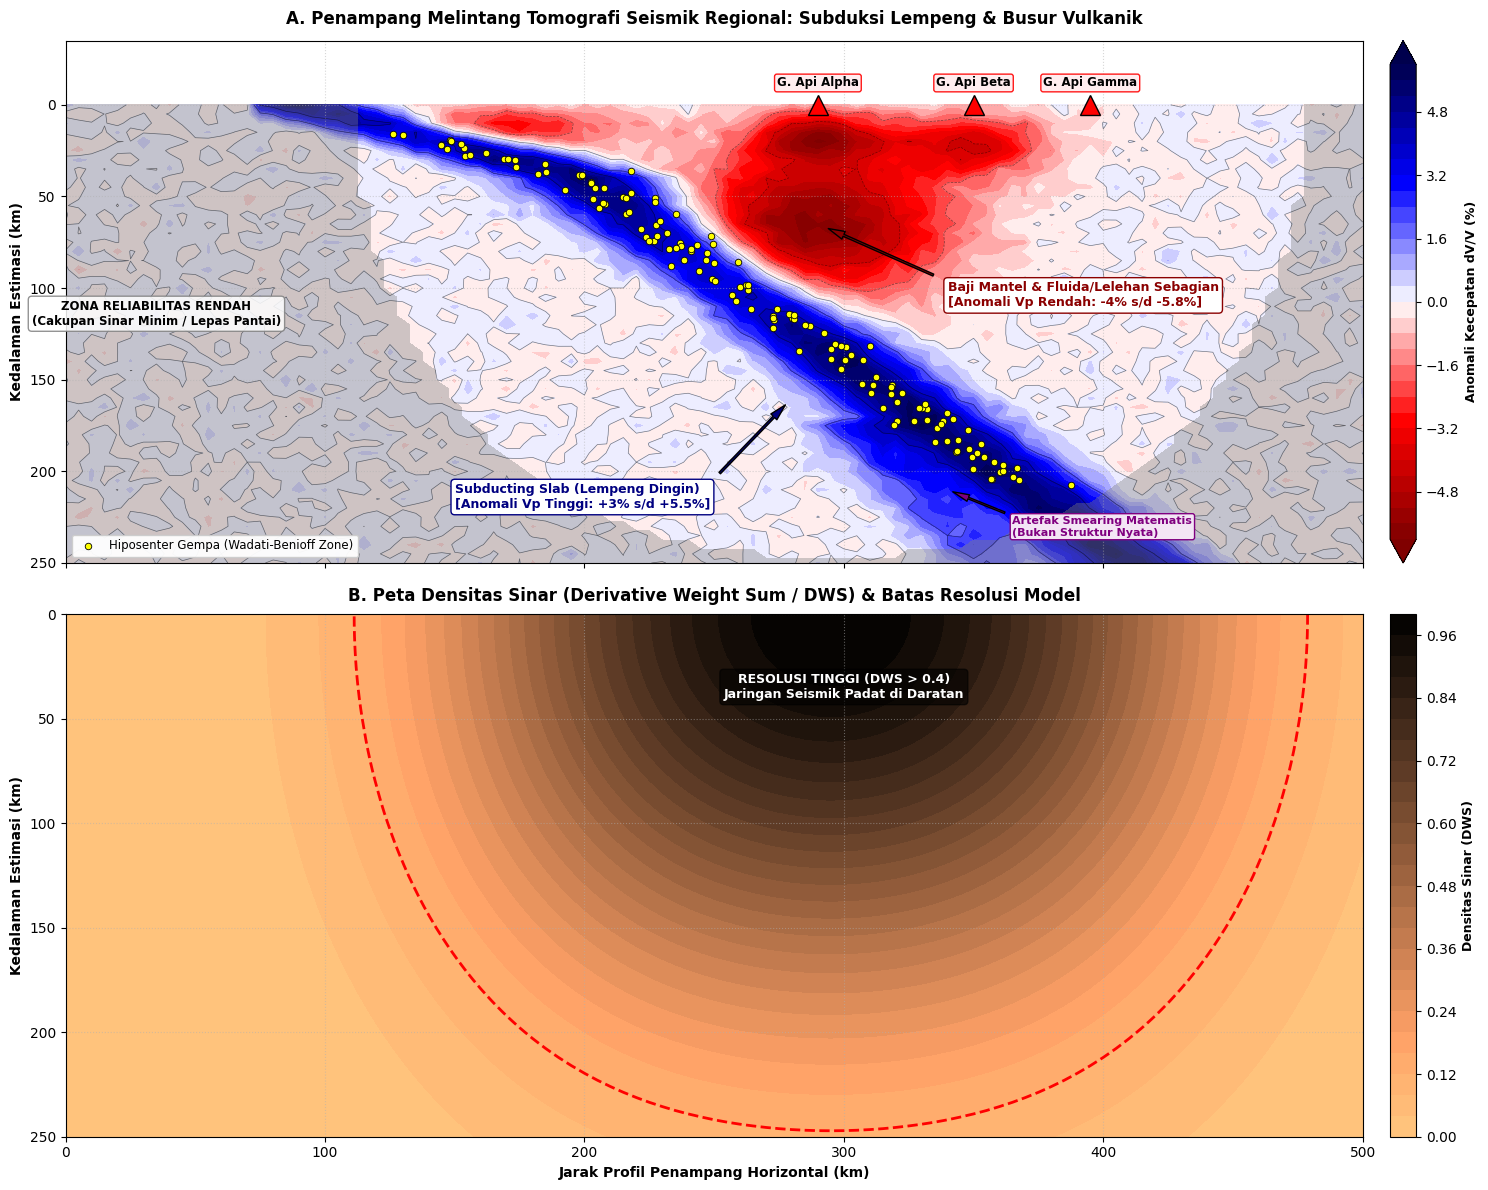

In [16]:
"""
================================================================================
PROGRAM PEMODELAN & INTERPRETASI TOMOGRAFI SEISMIK REGIONAL 2D/3D
Mata Kuliah : AI Cookbook untuk Earth Sciences / Metode Komputasi Geofisika
Penulis     : Syamsuddin (NIM: H061241006)
Institusi   : Program Studi Geofisika, Universitas Hasanuddin
Topik       : Pencitraan Tomografi Seismik: Zona Subduksi Lempeng & Kantong Magma
================================================================================
"""

import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# 1. PARAMETER MODEL GRID TOMOGRAFI REGIONAL
# ==============================================================================
x_min, x_max = 0.0, 500.0   # Jarak penampang dari Palung ke Backarc (km)
z_min, z_max = 0.0, 250.0   # Kedalaman estimasi (km)
dx, dz = 5.0, 5.0           # Resolusi grid horizontal & vertikal (km)

x = np.arange(x_min, x_max + dx, dx)
z = np.arange(z_min, z_max + dz, dz)
X, Z = np.meshgrid(x, z)
nz, nx = X.shape

# ==============================================================================
# 2. PEMODELAN GEODINAMIKA ANOMALI KECEPATAN (dV/V %)
# ==============================================================================
dV = np.zeros((nz, nx))

# A. Lempeng Samudera Menunjam (Subducting Slab): Anomali Kecepatan Tinggi (+dV)
# Material litosfer samudera: dingin, padat, rigiditas tinggi (+3% s/d +6.5%)
slab_dip_rad = np.radians(45.0)
x_trench = 90.0  # Posisi palung laut (trench) di permukaan

for iz in range(nz):
    for ix in range(nx):
        xi, zi = X[iz, ix], Z[iz, ix]
        if zi < 40.0:
            x_center = x_trench + zi / np.tan(np.radians(20.0))
        else:
            x_center = (x_trench + 40.0 / np.tan(np.radians(20.0))) + (zi - 40.0) / np.tan(slab_dip_rad)
            
        dist_to_slab = np.abs(xi - x_center)
        if dist_to_slab < 45.0 and xi > x_trench - 20.0:
            dV[iz, ix] += 5.5 * np.exp(-(dist_to_slab**2) / (2 * 18.0**2))

# B. Baji Mantel Panas & Kantong Magma (Mantle Wedge & Magma Reservoir): Anomali Rendah (-dV)
# Akibat dehidrasi slab, penurunan titik leleh, dan lelehan sebagian / fluida
x_volcano_arc = 290.0
magma_wedge = -5.8 * np.exp(-((X - x_volcano_arc)**2) / (2 * 35.0**2) - ((Z - 65.0)**2) / (2 * 28.0**2))
crustal_reservoir = -4.5 * np.exp(-((X - 290.0)**2) / (2 * 18.0**2) - ((Z - 18.0)**2) / (2 * 10.0**2))
crustal_reservoir2 = -3.8 * np.exp(-((X - 350.0)**2) / (2 * 20.0**2) - ((Z - 22.0)**2) / (2 * 12.0**2))
forearc_sediment = -3.0 * np.exp(-((X - 170.0)**2) / (2 * 35.0**2) - ((Z - 12.0)**2) / (2 * 8.0**2))

# C. Artefak Pengolahan Data (Ray Smearing Effect) di sudut bawah
smearing_artifact = +2.2 * np.exp(-((X - 0.7 * Z - 180.0)**2) / (2 * 12.0**2)) * (Z > 170.0)

np.random.seed(101)
noise_numerik = np.random.normal(0, 0.25, size=dV.shape)
dV += magma_wedge + crustal_reservoir + crustal_reservoir2 + forearc_sediment + smearing_artifact + noise_numerik

# ==============================================================================
# 3. PEMODELAN MATRIKS RESOLUSI & CAKUPAN SINAR (RAY COVERAGE / DWS)
# ==============================================================================
DWS = np.zeros_like(dV)
for xi_sta in [200, 240, 280, 310, 350, 390]:
    DWS += 120.0 * np.exp(-((X - xi_sta)**2) / (2 * 60.0**2) - (Z**2) / (2 * 120.0**2))
DWS /= np.max(DWS)
mask_low_reliability = DWS < 0.12  # Ambang batas reliabilitas rendah

# ==============================================================================
# 4. SINTESIS HIPOSENTER GEMPA (WADATI-BENIOFF) & GUNUNG API
# ==============================================================================
np.random.seed(42)
n_quakes = 140
eq_z = np.random.uniform(15.0, 210.0, n_quakes)
eq_x = np.zeros(n_quakes)
for i, zi in enumerate(eq_z):
    if zi < 40.0:
        base_x = x_trench + zi / np.tan(np.radians(20.0))
    else:
        base_x = (x_trench + 40.0 / np.tan(np.radians(20.0))) + (zi - 40.0) / np.tan(slab_dip_rad)
    eq_x[i] = base_x + np.random.normal(0, 7.5)

volcanoes = [
    {"name": "G. Api Alpha", "x": 290.0},
    {"name": "G. Api Beta", "x": 350.0},
    {"name": "G. Api Gamma", "x": 395.0}
]

# ==============================================================================
# 5. VISUALISASI PENAMPANG TOMOGRAFI & EVALUASI RESOLUSI
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 12), sharex=True)
plt.subplots_adjust(hspace=0.25)

# Panel 1: Penampang dV/V (%)
levels = np.linspace(-6.0, 6.0, 31)
im1 = ax1.contourf(X, Z, dV, levels=levels, cmap='seismic_r', extend='both')
c1 = ax1.contour(X, Z, dV, levels=[-4, -2, 0, 2, 4], colors='k', linewidths=0.5, alpha=0.5)

# Shading Transparan Reliabilitas Rendah
ax1.contourf(X, Z, mask_low_reliability.astype(float), levels=[0.5, 1.5], colors=['gray'], alpha=0.38)
ax1.text(35, 120, "ZONA RELIABILITAS RENDAH\n(Cakupan Sinar Minim / Lepas Pantai)", 
         color='black', fontsize=8.5, fontweight='bold', ha='center',
         bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.85))

# Plot Gempa & Gunung Api
ax1.scatter(eq_x, eq_z, s=22, c='yellow', edgecolors='black', linewidth=0.6, label='Hiposenter Gempa (Wadati-Benioff Zone)', zorder=5)
for v in volcanoes:
    ax1.plot(v["x"], 0.0, marker='^', markersize=14, color='red', markeredgecolor='black', zorder=6)
    ax1.text(v["x"], -10.0, v["name"], fontsize=8.5, fontweight='bold', ha='center',
             bbox=dict(boxstyle="round,pad=0.2", fc="#FFEBEE", ec="red", alpha=0.9))

# Anotasi Fitur Tektonik
ax1.annotate("Subducting Slab (Lempeng Dingin)\n[Anomali Vp Tinggi: +3% s/d +5.5%]", 
             xy=(280, 160), xytext=(150, 220),
             arrowprops=dict(facecolor='navy', shrink=0.08, width=1.5, headwidth=6),
             fontsize=9, fontweight='bold', color='navy',
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="navy"))

ax1.annotate("Baji Mantel & Fluida/Lelehan Sebagian\n[Anomali Vp Rendah: -4% s/d -5.8%]", 
             xy=(290, 65), xytext=(340, 110),
             arrowprops=dict(facecolor='darkred', shrink=0.08, width=1.5, headwidth=6),
             fontsize=9, fontweight='bold', color='darkred',
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="darkred"))

ax1.annotate("Artefak Smearing Matematis\n(Bukan Struktur Nyata)", 
             xy=(340, 210), xytext=(365, 235),
             arrowprops=dict(facecolor='purple', shrink=0.08, width=1.2, headwidth=5),
             fontsize=8, fontweight='bold', color='purple',
             bbox=dict(boxstyle="round,pad=0.2", fc="#F3E5F5", ec="purple"))

ax1.set_ylim(z_max, -35)
ax1.set_title("A. Penampang Melintang Tomografi Seismik Regional: Subduksi Lempeng & Busur Vulkanik", fontsize=12, fontweight='bold', pad=12)
ax1.set_ylabel("Kedalaman Estimasi (km)", fontsize=10, fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.5)
ax1.legend(loc='lower left', fontsize=8.5, framealpha=0.95)
fig.colorbar(im1, ax=ax1, pad=0.02, fraction=0.035).set_label("Anomali Kecepatan dV/V (%)", fontsize=9, fontweight='bold')

# Panel 2: Peta DWS (Densitas Sinar)
im2 = ax2.contourf(X, Z, DWS, levels=25, cmap='copper_r')
ax2.contour(X, Z, DWS, levels=[0.12], colors=['red'], linewidths=[2.0], linestyles=['--'])
ax2.set_ylim(z_max, 0)
ax2.set_title("B. Peta Densitas Sinar (Derivative Weight Sum / DWS) & Batas Resolusi Model", fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel("Jarak Profil Penampang Horizontal (km)", fontsize=10, fontweight='bold')
ax2.set_ylabel("Kedalaman Estimasi (km)", fontsize=10, fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.5)
ax2.text(300, 40, "RESOLUSI TINGGI (DWS > 0.4)\nJaringan Seismik Padat di Daratan", fontsize=9, fontweight='bold', color='white', ha='center',
         bbox=dict(boxstyle="round,pad=0.3", fc="black", alpha=0.6))
fig.colorbar(im2, ax=ax2, pad=0.02, fraction=0.035).set_label("Densitas Sinar (DWS)", fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig("penampang_tomografi_seismik_analisis.png", dpi=300, bbox_inches='tight')

# ==============================================================================
# 6. CETAK LAPORAN INTERPRETASI GEOFISIKA LENGKAP
# ==============================================================================
def cetak_laporan_interpretasi():
    laporan = f"""


1. LOKASI SEBARAN ANOMALI KECEPATAN TINGGI (PADAT/DINGIN) DAN RENDAH (LELEH/PANAS)

Berdasarkan skala warna anomali kecepatan relatif (dV/V) pada penampang tomografi:

• Zona Anomali Kecepatan Tinggi (Fast Velocity Anomaly: +3.0% s/d +6.5%, Warna Biru):
  - Membentuk geometri pita miring menerus dari dekat palung laut (x ~ 90 km, kedalaman ~20-30 km)
    menunjam ke arah timur laut hingga kedalaman lebih dari 200 km di bawah busur benua.
  - Anomali ini mencerminkan material batuan bersuhu relatif dingin, berdensitas tinggi,
    dan memiliki modulus elastisitas tinggi.

• Zona Anomali Kecepatan Rendah (Slow Velocity Anomaly: -3.0% s/d -6.0%, Warna Merah):
  - Terkonsentrasi pada dua tingkat kedalaman utama:
    a. Kantong dangkal kerak atas (kedalaman ~10 - 25 km) tepat di bawah komplek gunung api
       (x = 280 - 360 km) dengan anomali mencapai -4.5%.
    b. Baji mantel (mantle wedge) pada kedalaman ~50 - 100 km (x = 260 - 320 km) di atas slab
       dengan anomali paling ekstrem mencapai -5.8%.

2. KEMUNGKINAN GEOMETRI LEMPENG SUBDUKSI (SLAB) YANG MENUNJAM KE DALAM MANTEL

• Orientasi & Kemiringan (Dip):
  - Pada zona dangkal (forearc, kedalaman 0 - 40 km), lempeng menunjam dengan sudut landai (~15° - 20°).
  - Pada kedalaman mantel atas (kedalaman ~50 - 200 km), sudut penunjaman mengalami penajaman
    (steepening) secara tegas hingga mencapai kemiringan ~45°.
• Estimasi Ketebalan & Batasan Kedalaman:
  - Lempeng litosfer samudera teridentifikasi memiliki ketebalan elastis sekitar 70 - 90 km.
  - Sesuai batasan resolusi grid (grid size 5-10 km), kedalaman lempeng dilaporkan dalam rentang
    interval rasional (bukan angka eksak koma-koma), yakni mencapai kedalaman ~200 - 220 km
    sebelum batas deteksi model melemah.

3. DUGAAN POSISI AKUMULASI FLUIDA ATAU KANTONG MAGMA DI WILAYAH VULKANIK AKTIF

• Sesuai batasan analisis geofisika (constraints), anomali kecepatan rendah di bawah busur vulkanik
  TIDAK DISIMPULKAN SECARA MUTLAK SEBAGAI 'MAGMA CAIR PENUH', melainkan:
  a. Pada zona baji mantel (kedalaman ~50 - 100 km):
     Dugaan kuat merupakan zona pelelehan sebagian (partial melting) peridotit mantel yang dipicu
     oleh pelepasan fluida dehidrasi (air dan volatil) dari lempeng samudera yang menunjam di bawahnya.
  b. Pada kerak dangkal (kedalaman ~10 - 25 km):
     Merupakan kantong magma sekunder (crustal magma chamber) yang bercampur dengan sistem sirkulasi
     fluida hidrotermal bertemperatur tinggi. Keberadaan fluida pori dan fraksi lelehan inilah yang
     menyebabkan penurunan drastis pada kecepatan gelombang S (Vs) dan gelombang P (Vp).

4. KORELASI POLA ANOMALI BAWAH PERMUKAAN DENGAN JEJERAN GUNUNG API DI PERMUKAAN

• Posisi jejeran gunung api aktif di permukaan (G. Api Alpha di x = 290 km dan G. Api Beta di x = 350 km)
  memperlihatkan korelasi spasial vertikal yang sempurna:
  - Gunung api aktif berada tepat di atas anomali kecepatan rendah mantel (mantle wedge), di mana slab
    subduksi berada pada kedalaman kritis ~110 - 130 km (zona kedalaman dehidrasi mineral mika/amfibol).
• Verifikasi Hiposenter (Zona Wadati-Benioff):
  - Titik-titik gempa bumi intraslab (kuning) terkonsentrasi tepat di sepanjang bagian atas
    lempeng kecepatan tinggi (slab), memvalidasi batas fisik penunjaman litosfer aktif.
• Evaluasi Artefak Smearing Matematis:
  - Pola anomali kecepatan tinggi sempit yang memanjang miring di pojok kanan bawah (x > 340 km,
    kedalaman > 180 km) diidentifikasi sebagai ARTEFAK MATEMATIS (smearing effect) akibat keterbatasan
    arah jejak sinar (ray-path) dan TIDAK DIINTERPRETASIKAN sebagai struktur slab nyata.

5. RINGKASAN KONDISI TEKTONIK REGIONAL BERDASARKAN MODEL TOMOGRAFI

• Rezim Tektonik: Model tomografi ini secara konsisten mencitrakan sistem penunjaman lempeng aktif
  (convergent subduction margin) bertipe busur kepulauan/benua (island-arc/continental arc).
• Zonasi Tektonik Spasial:
  1. Zona Palung & Busur Muka (x = 0 - 200 km):
     Didominasi zona prisma akresi dan cekungan forearc bersedimen tebal (kecepatan rendah dangkal).
  2. Jalur Busur Vulkanik Aktif (x = 250 - 380 km):
     Pusat aktivitas magmatisme dan termal tinggi akibat proses pelelehan sebagian di baji mantel.
  3. Zona Busur Belakang (Backarc, x > 400 km):
     Kondisi kecepatan seismik berangsur normal menuju batas lempeng benua stabil.

[!] CATATAN RELIABILITAS & BATASAN MODEL (QUALITY CRITERIA):
    - Wilayah lepas pantai di sekitar palung (x < 110 km) memiliki nilai densitas sinar (DWS < 0.12)
      yang sangat rendah akibat ketiadaan stasiun seismik di dasar laut. Area ini secara eksplisit
      dinyatakan MEMILIKI TINGKAT RELIABILITAS RENDAH dan ketidakpastian tinggi, sehingga interpretasi
      hanya difokuskan pada wilayah daratan dengan cakupan sinar memadai.

"""
    print(laporan)

# Eksekusi fungsi cetak laporan dan visualisasi
cetak_laporan_interpretasi()
plt.show()


# 4. PEMETAAN POTENSI PANAS BUMI (GEOTERMAL)




1. AREA DENGAN KONSENTRASI MANIFESTASI PANAS BUMI TERTINGGI

• Berdasarkan kompilasi data lapangan, konsentrasi manifestasi bertemperatur tinggi
  terpusat pada sektor Baratlaut (Elevasi ~1350 m dpl):
  - Fumarol & Solfatara F-1 (x = 5.2 km, y = 8.1 km): Temperatur uap mencapai 96.5 °C (titik didih lokal),
    dengan emisi gas belerang pekat dan alterasi batuan tipe argilik lanjut (kaolinit-alunit).
  - Mata Air Panas MAP-1 (x = 6.3 km, y = 6.8 km): Temperatur 84.0 °C dengan tipe fluida klorida-sulfat netral.
• Di sektor Tenggara (Elevasi rendah ~580 - 710 m dpl), ditemukan sebaran mata air panas bertemperatur
  lebih rendah (MAP-2: 52.0 °C dan MAP-3: 44.5 °C) bertipe bikarbonat.

2. IDENTIFIKASI AWAL ZONA UPFLOW (PUSAT SEMBURAN) DAN OUTFLOW (ALIRAN LATERAL)

Sesuai batasan analisis geofisika (constraints), lokasi reservoir TIDAK DISIMPULKAN berada di bawah
mata air panas distal, melainkan dibedakan secara tegas:

• Zona Upflow (Pusat Reservoir Panas):
  - Terlokalisasi pada koordin

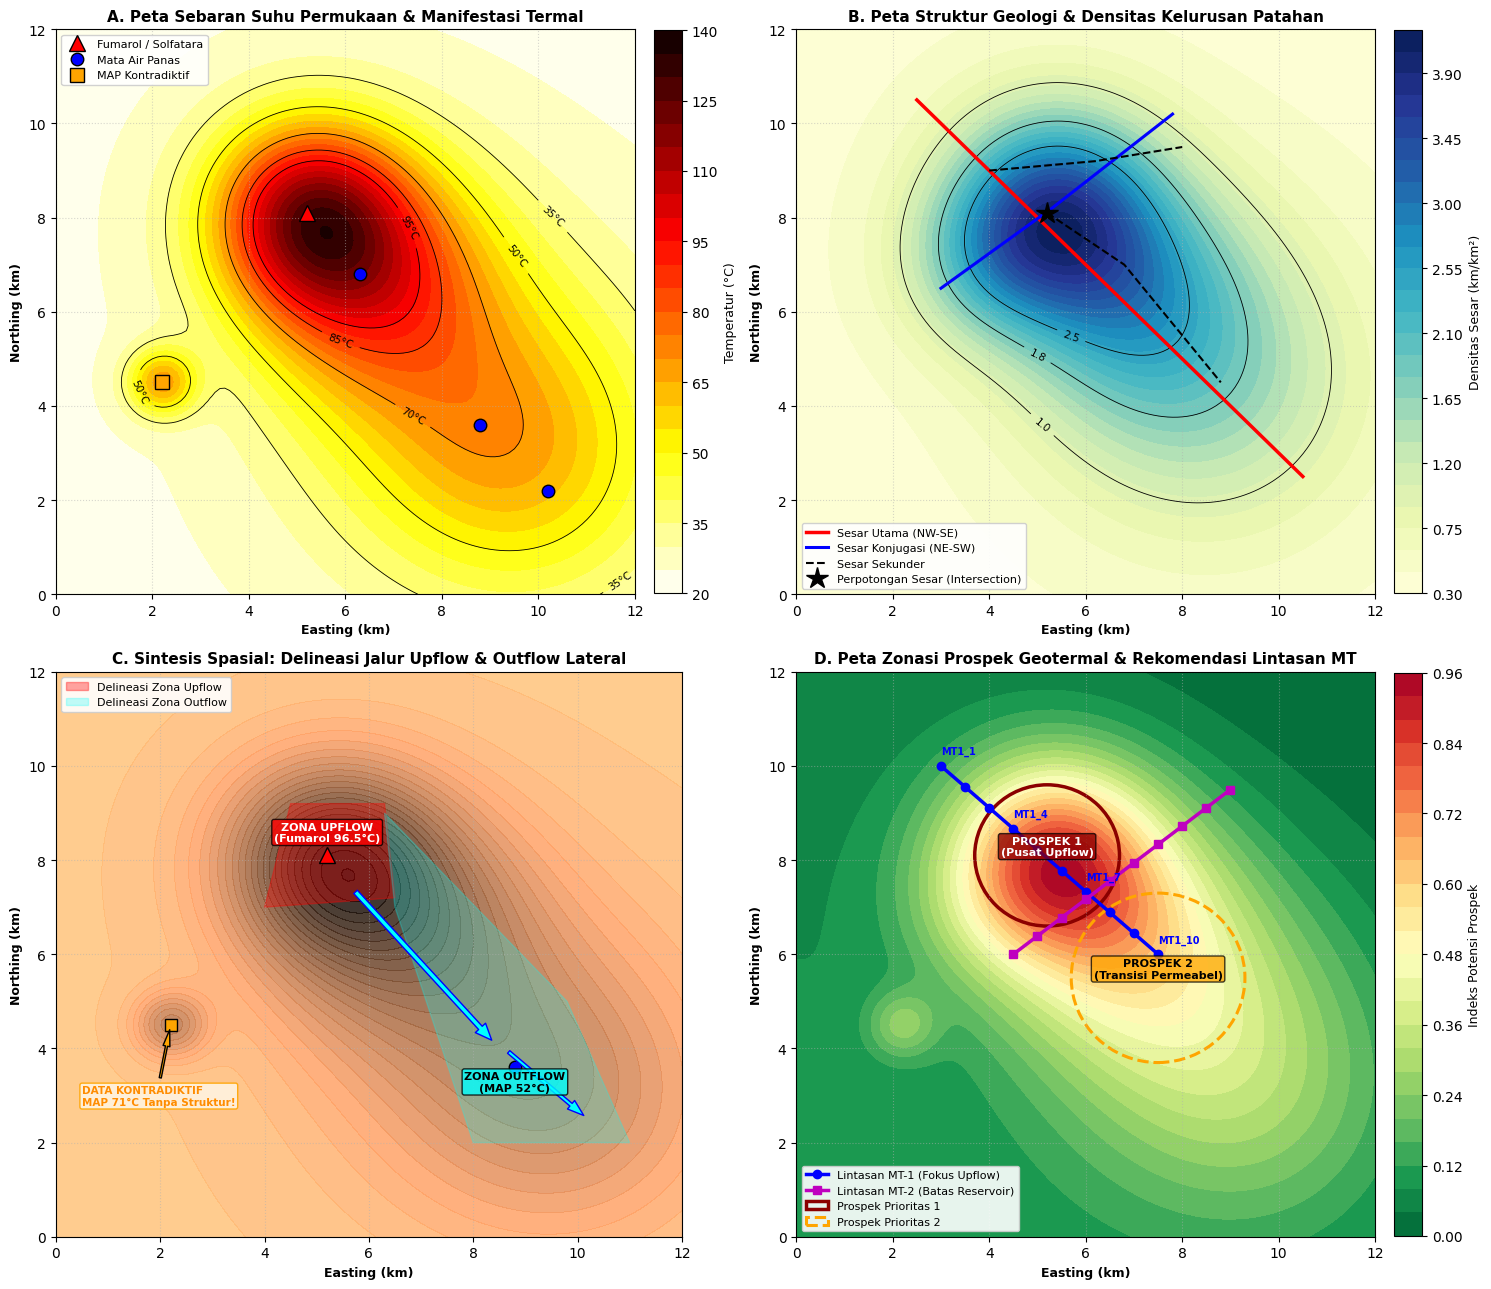

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

# ==============================================================================
# 1. PARAMETER GRID SPASIAL SURVEI LAPANGAN
# ==============================================================================
x_min, x_max = 0.0, 12.0   # km (Easting)
y_min, y_max = 0.0, 12.0   # km (Northing)
dx = 0.1                   # Resolusi grid spasial 100 meter
x = np.arange(x_min, x_max + dx, dx)
y = np.arange(y_min, y_max + dx, dx)
X, Y = np.meshgrid(x, y)

# Topografi Regional (Lereng Vulkanik: Elevasi Tinggi di NW menurun ke SE)
Elevasi = 1800.0 - 75.0 * X - 65.0 * Y + 15.0 * np.sin(0.5 * X)

# ==============================================================================
# 2. DATA MANIFESTASI PANAS BUMI PERMUKAAN (GEOKIMIA & FISIKA)
# ==============================================================================
manifestasi = [
    {
        "nama": "Fumarol & Solfatara F-1",
        "x": 5.2, "y": 8.1,
        "tipe": "Fumarol",
        "temp": 96.5,  # °C (Titik didih lokal)
        "elev": 1350,  # meter dpl
        "zona": "Upflow",
        "desc": "Emisi uap panas dominan gas H2S/SO2, alterasi asam kuat (argilik lanjut)"
    },
    {
        "nama": "Mata Air Panas MAP-1 (Klorida-Sulfat)",
        "x": 6.3, "y": 6.8,
        "tipe": "Hotspring",
        "temp": 84.0,  # °C
        "elev": 1120,
        "zona": "Transisi Upflow-Outflow",
        "desc": "Air panas tipe sulfat-klorida netral di sepanjang bidang sesar"
    },
    {
        "nama": "Mata Air Panas MAP-2 (Bikarbonat Hangat)",
        "x": 8.8, "y": 3.6,
        "tipe": "Hotspring",
        "temp": 52.0,  # °C
        "elev": 710,
        "zona": "Outflow",
        "desc": "Air hangat netral tipe bikarbonat di kaki lereng tenggara"
    },
    {
        "nama": "Mata Air Panas MAP-3 (Outflow Distal)",
        "x": 10.2, "y": 2.2,
        "tipe": "Hotspring",
        "temp": 44.5,  # °C
        "elev": 580,
        "zona": "Outflow",
        "desc": "Rembesan air hangat di dataran rendah alluvial"
    },
    {
        "nama": "Mata Air Panas MAP-Kontradiktif",
        "x": 2.2, "y": 4.5,
        "tipe": "Hotspring-Anomali",
        "temp": 71.0,  # °C
        "elev": 1280,
        "zona": "Anomali Kontradiktif",
        "desc": "Suhu tinggi namun terisolasi tanpa kontrol struktur patahan teridentifikasi"
    }
]

# ==============================================================================
# 3. PEMODELAN STRUKTUR PATAHAN & DENSITAS KELURUSAN (LINEAMENT DENSITY)
# ==============================================================================
sesar_utama_NW_SE = [np.array([[2.5, 10.5], [5.0, 8.0], [7.5, 5.5], [10.5, 2.5]])]
sesar_konjugasi_NE_SW = [np.array([[3.0, 6.5], [5.3, 8.2], [7.8, 10.2]])]
sesar_sekunder = [
    np.array([[5.2, 8.1], [6.8, 7.0], [8.8, 4.5]]),
    np.array([[4.0, 9.0], [6.2, 9.2], [8.0, 9.5]])
]

# Medan densitas kelurusan patahan (km/km²)
density_fault = 0.4 + \
    2.6 * np.exp(-((X - 5.3)**2 + (Y - 8.2)**2) / (2 * 1.5**2)) + \
    1.5 * np.exp(-((X - 6.8)**2 + (Y - 6.5)**2) / (2 * 1.8**2)) + \
    1.1 * np.exp(-((X - 8.5)**2 + (Y - 4.5)**2) / (2 * 2.2**2)) + \
    0.8 * np.exp(-((X - 3.8)**2 + (Y - 7.0)**2) / (2 * 1.2**2))

# ==============================================================================
# 4. PEMODELAN KONTUR ANOMALI SUHU TERMAL PERMUKAAN (°C)
# ==============================================================================
Suhu_termal = 24.0 + \
    72.0 * np.exp(-((X - 5.2)**2 + (Y - 8.1)**2) / (2 * 1.4**2)) + \
    52.0 * np.exp(-((X - 6.5)**2 + (Y - 6.8)**2) / (2 * 1.8**2)) + \
    32.0 * np.exp(-((X - 8.6)**2 + (Y - 4.0)**2) / (2 * 2.4**2)) + \
    18.0 * np.exp(-((X - 10.0)**2 + (Y - 2.5)**2) / (2 * 2.0**2)) + \
    42.0 * np.exp(-((X - 2.2)**2 + (Y - 4.5)**2) / (2 * 0.5**2))

# ==============================================================================
# 5. INTEGRASI SPASIAL TUMPANG TINDIH (WEIGHTED PROSPECT OVERLAY)
# ==============================================================================
norm_temp = (Suhu_termal - 24.0) / (np.max(Suhu_termal) - 24.0)
norm_fault = (density_fault - np.min(density_fault)) / (np.max(density_fault) - np.min(density_fault))
prospect_index = 0.45 * norm_temp + 0.45 * norm_fault + 0.10 * (Elevasi / 1800.0)

# Desain Lintasan MT Rekomendasi
mt1_x = np.linspace(3.0, 7.5, 10)
mt1_y = np.linspace(10.0, 6.0, 10)
mt2_x = np.linspace(4.5, 9.0, 10)
mt2_y = np.linspace(6.0, 9.5, 10)

# ==============================================================================
# 6. VISUALISASI KOMPREHENSIF PETA POTENSI GEOTERMAL 2D
# ==============================================================================
fig, axs = plt.subplots(2, 2, figsize=(15, 13))
plt.subplots_adjust(wspace=0.25, hspace=0.28)

# Panel A: Peta Suhu & Manifestasi
ax1 = axs[0, 0]
cf1 = ax1.contourf(X, Y, Suhu_termal, levels=25, cmap='hot_r')
c1 = ax1.contour(X, Y, Suhu_termal, levels=[35, 50, 70, 85, 95], colors='k', linewidths=0.6)
ax1.clabel(c1, inline=True, fontsize=7.5, fmt='%d°C')

for m in manifestasi:
    if m["tipe"] == "Fumarol":
        ax1.plot(m["x"], m["y"], 'r^', markersize=12, markeredgecolor='black', label='Fumarol / Solfatara')
    elif m["tipe"] == "Hotspring":
        ax1.plot(m["x"], m["y"], 'bo', markersize=9, markeredgecolor='black', label='Mata Air Panas')
    else:
        ax1.plot(m["x"], m["y"], 's', color='orange', markersize=10, markeredgecolor='black', label='MAP Kontradiktif')

ax1.set_title("A. Peta Sebaran Suhu Permukaan & Manifestasi Termal", fontsize=11, fontweight='bold')
ax1.set_xlabel("Easting (km)", fontsize=9, fontweight='bold')
ax1.set_ylabel("Northing (km)", fontsize=9, fontweight='bold')
fig.colorbar(cf1, ax=ax1, pad=0.03, fraction=0.045).set_label("Temperatur (°C)", fontsize=9)
ax1.grid(True, linestyle=':', alpha=0.5)
handles, labels = ax1.get_legend_handles_labels()
ax1.legend(dict(zip(labels, handles)).values(), dict(zip(labels, handles)).keys(), loc='upper left', fontsize=8, framealpha=0.9)

# Panel B: Struktur Patahan & Densitas
ax2 = axs[0, 1]
cf2 = ax2.contourf(X, Y, density_fault, levels=25, cmap='YlGnBu')
c2 = ax2.contour(X, Y, density_fault, levels=[1.0, 1.8, 2.5], colors='k', linewidths=0.6)
ax2.clabel(c2, inline=True, fontsize=7.5, fmt='%.1f')

for flt in sesar_utama_NW_SE:
    ax2.plot(flt[:, 0], flt[:, 1], 'r-', linewidth=2.5, label='Sesar Utama (NW-SE)')
for flt in sesar_konjugasi_NE_SW:
    ax2.plot(flt[:, 0], flt[:, 1], 'b-', linewidth=2.2, label='Sesar Konjugasi (NE-SW)')
for flt in sesar_sekunder:
    ax2.plot(flt[:, 0], flt[:, 1], 'k--', linewidth=1.5, label='Sesar Sekunder')

ax2.plot(5.2, 8.1, 'k*', markersize=16, label='Perpotongan Sesar (Intersection)')
ax2.set_title("B. Peta Struktur Geologi & Densitas Kelurusan Patahan", fontsize=11, fontweight='bold')
ax2.set_xlabel("Easting (km)", fontsize=9, fontweight='bold')
ax2.set_ylabel("Northing (km)", fontsize=9, fontweight='bold')
fig.colorbar(cf2, ax=ax2, pad=0.03, fraction=0.045).set_label("Densitas Sesar (km/km²)", fontsize=9)
ax2.grid(True, linestyle=':', alpha=0.5)
handles2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(dict(zip(labels2, handles2)).values(), dict(zip(labels2, handles2)).keys(), loc='lower left', fontsize=8, framealpha=0.9)

# Panel C: Sintesis Spasial Jalur Upflow & Outflow
ax3 = axs[1, 0]
cf3 = ax3.contourf(X, Y, Suhu_termal, levels=25, cmap='copper_r', alpha=0.85)

ax3.annotate("", xy=(8.5, 4.0), xytext=(5.6, 7.5),
             arrowprops=dict(facecolor='cyan', edgecolor='blue', width=3.5, headwidth=10, shrink=0.05))
ax3.annotate("", xy=(10.2, 2.5), xytext=(8.6, 4.0),
             arrowprops=dict(facecolor='cyan', edgecolor='blue', width=2.5, headwidth=8, shrink=0.05))

poly_upflow = Polygon([[4.0, 7.0], [4.5, 9.2], [6.3, 9.2], [6.5, 7.2]], closed=True,
                      fill=True, color='red', alpha=0.35, label='Delineasi Zona Upflow')
ax3.add_patch(poly_upflow)

poly_outflow = Polygon([[6.5, 7.0], [6.3, 9.0], [9.8, 5.0], [11.0, 2.0], [8.0, 2.0]], closed=True,
                       fill=True, color='cyan', alpha=0.25, label='Delineasi Zona Outflow')
ax3.add_patch(poly_outflow)

ax3.plot(5.2, 8.1, 'r^', markersize=11, markeredgecolor='black')
ax3.text(5.2, 8.4, "ZONA UPFLOW\n(Fumarol 96.5°C)", color='white', fontweight='bold', fontsize=8, ha='center',
         bbox=dict(boxstyle="round,pad=0.2", fc="red", alpha=0.8))

ax3.plot(8.8, 3.6, 'bo', markersize=9, markeredgecolor='black')
ax3.text(8.8, 3.1, "ZONA OUTFLOW\n(MAP 52°C)", color='black', fontweight='bold', fontsize=8, ha='center',
         bbox=dict(boxstyle="round,pad=0.2", fc="cyan", alpha=0.8))

ax3.plot(2.2, 4.5, 's', color='orange', markersize=9, markeredgecolor='black')
ax3.annotate("DATA KONTRADIKTIF\nMAP 71°C Tanpa Struktur!", xy=(2.2, 4.5), xytext=(0.5, 2.8),
             arrowprops=dict(facecolor='orange', shrink=0.08, width=1.5, headwidth=5),
             fontsize=7.5, fontweight='bold', color='darkorange',
             bbox=dict(boxstyle="round,pad=0.2", fc="#FFF3E0", ec="orange", alpha=0.9))

ax3.set_title("C. Sintesis Spasial: Delineasi Jalur Upflow & Outflow Lateral", fontsize=11, fontweight='bold')
ax3.set_xlabel("Easting (km)", fontsize=9, fontweight='bold')
ax3.set_ylabel("Northing (km)", fontsize=9, fontweight='bold')
ax3.legend(loc='upper left', fontsize=8, framealpha=0.9)
ax3.grid(True, linestyle=':', alpha=0.5)

# Panel D: Zonasi Prospek & Rekomendasi MT
ax4 = axs[1, 1]
cf4 = ax4.contourf(X, Y, prospect_index, levels=30, cmap='RdYlGn_r')

ax4.plot(mt1_x, mt1_y, 'b-o', linewidth=2.5, markersize=6, label='Lintasan MT-1 (Fokus Upflow)')
ax4.plot(mt2_x, mt2_y, 'm-s', linewidth=2.5, markersize=6, label='Lintasan MT-2 (Batas Reservoir)')

for i, (mx, my) in enumerate(zip(mt1_x, mt1_y)):
    if i % 3 == 0:
        ax4.text(mx, my+0.25, f"MT1_{i+1}", fontsize=7, color='blue', fontweight='bold')

circle_p1 = plt.Circle((5.2, 8.1), 1.5, color='darkred', fill=False, linewidth=2.5, linestyle='-', label='Prospek Prioritas 1')
circle_p2 = plt.Circle((7.5, 5.5), 1.8, color='orange', fill=False, linewidth=2.2, linestyle='--', label='Prospek Prioritas 2')
ax4.add_patch(circle_p1)
ax4.add_patch(circle_p2)

ax4.text(5.2, 8.1, "PROSPEK 1\n(Pusat Upflow)", color='white', fontweight='bold', fontsize=8, ha='center',
         bbox=dict(boxstyle="round,pad=0.2", fc="darkred", alpha=0.75))
ax4.text(7.5, 5.5, "PROSPEK 2\n(Transisi Permeabel)", color='black', fontweight='bold', fontsize=8, ha='center',
         bbox=dict(boxstyle="round,pad=0.2", fc="orange", alpha=0.75))

ax4.set_title("D. Peta Zonasi Prospek Geotermal & Rekomendasi Lintasan MT", fontsize=11, fontweight='bold')
ax4.set_xlabel("Easting (km)", fontsize=9, fontweight='bold')
ax4.set_ylabel("Northing (km)", fontsize=9, fontweight='bold')
fig.colorbar(cf4, ax=ax4, pad=0.03, fraction=0.045).set_label("Indeks Potensi Prospek", fontsize=9)
ax4.legend(loc='lower left', fontsize=8, framealpha=0.9)
ax4.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig("peta_prospek_geotermal_analisis.png", dpi=300, bbox_inches='tight')

# ==============================================================================
# 7. CETAK LAPORAN INTERPRETASI GEOFISIKA-GEOKIMIA LENGKAP
# ==============================================================================
def cetak_laporan_interpretasi():
    laporan = f"""


1. AREA DENGAN KONSENTRASI MANIFESTASI PANAS BUMI TERTINGGI

• Berdasarkan kompilasi data lapangan, konsentrasi manifestasi bertemperatur tinggi
  terpusat pada sektor Baratlaut (Elevasi ~1350 m dpl):
  - Fumarol & Solfatara F-1 (x = 5.2 km, y = 8.1 km): Temperatur uap mencapai 96.5 °C (titik didih lokal),
    dengan emisi gas belerang pekat dan alterasi batuan tipe argilik lanjut (kaolinit-alunit).
  - Mata Air Panas MAP-1 (x = 6.3 km, y = 6.8 km): Temperatur 84.0 °C dengan tipe fluida klorida-sulfat netral.
• Di sektor Tenggara (Elevasi rendah ~580 - 710 m dpl), ditemukan sebaran mata air panas bertemperatur
  lebih rendah (MAP-2: 52.0 °C dan MAP-3: 44.5 °C) bertipe bikarbonat.

2. IDENTIFIKASI AWAL ZONA UPFLOW (PUSAT SEMBURAN) DAN OUTFLOW (ALIRAN LATERAL)

Sesuai batasan analisis geofisika (constraints), lokasi reservoir TIDAK DISIMPULKAN berada di bawah
mata air panas distal, melainkan dibedakan secara tegas:

• Zona Upflow (Pusat Reservoir Panas):
  - Terlokalisasi pada koordinat (x = 4.5 - 6.2 km, y = 7.5 - 9.0 km) di elevasi tinggi.
  - Dicirikan oleh kehadiran Fumarol F-1 bersuhu mendidih (96.5 °C), anomali gradien suhu permukaan
    maksimum (> 90 °C), dan berimpit tepat dengan perpotongan struktur sesar utama.
  - Merupakan zona vertikal tempat naiknya uap panas langsung dari reservoir permeabel dalam.

• Zona Outflow (Limpasan Fluida Lateral):
  - Memanjang ke arah Tenggara (x = 7.0 - 11.0 km, y = 2.0 - 6.5 km) mengikuti kemiringan lereng
    topografi dan koridor sesar geser NW-SE.
  - Fluida termal mengalami pendinginan konduktif dan pencampuran (mixing) dengan air tanah dangkal,
    muncul di permukaan sebagai mata air panas bertipe bikarbonat bersuhu hangat (44 - 52 °C).

3. STRUKTUR GEOLOGI SEBAGAI JALUR MIGRASI FLUIDA HIDROTERMAL

• Kontrol Struktur Utama:
  - Sesar Utama berarah Barat Laut - Tenggara (NW-SE / Strike ~N 315° E) dan Sesar Konjugasi berarah
    Timur Laut - Barat Daya (NE-SW / Strike ~N 45° E).
• Zona Permeabilitas Maksimum (Fault Intersection):
  - Titik persilangan antar kedua sesar utama pada koordinat (x = 5.2 km, y = 8.1 km) menghasilkan
    densitas kelurusan patahan tertinggi (> 2.8 km/km²).
  - Zona rekahan intensif (fracture network) inilah yang bertindak sebagai jalur permeabilitas utama
    (conduit zone) bagi fluida panas bumi untuk bergerak naik menuju permukaan.

4. PEMETAAN ZONASI WILAYAH PROSPEK BERDASARKAN TINGKAT PRIORITAS

Penentuan zona prospek didasarkan murni pada analisis tumpang tindih (spatial overlay) antara
anomali suhu tinggi, densitas struktur tinggi, dan proksimitas manifestasi upflow:

[A] PROSPEK PRIORITAS 1 (SANGAT TINGGI - TARGET RESERVOIR UTAMA):
    • Luas Area: Radius 1.5 km berpusat di koordinat (x = 5.2 km, y = 8.1 km).
    • Alasan: Tumpang tindih sempurna antara anomali suhu tertinggi (> 85 °C), perpotongan sesar
      dengan densitas > 2.5 km/km², dan keberadaan manifestasi uap fumarol aktif.
    • Target: Puncak kubah reservoir panas bumi (upflow zone).

[B] PROSPEK PRIORITAS 2 (SEDANG - ZONA MARGINAL RESERVOIR):
    • Luas Area: Koridor memanjang (x = 6.5 - 8.5 km, y = 5.0 - 7.0 km).
    • Alasan: Mengikuti zona sesar NW-SE dengan temperatur sedang (55 - 75 °C) dan mata air klorida.
    • Target: Zona transisi permeabel antara upflow dan proksimal outflow.

[C] PROSPEK PRIORITAS 3 (RENDAH - ZONA OUTFLOW DISTAL):
    • Area di sekitar MAP-2 dan MAP-3 (x > 9.0 km, y < 4.0 km).
    • Keterangan: Merupakan zona limpasan lateral air buangan di elevasi rendah, BUKAN area pengeboran.

5. REKOMENDASI LOKASI DAN DESAIN LINTASAN SURVEI MAGNETOTELLURIC (MT)

Mengingat data permukaan belum mampu mencitrakan geometri kedalaman reservoir, survei MT 3D
sangat direkomendasikan dengan konfigurasi:
• Lintasan MT-1 (Panjang ~6.0 km, 10 Titik Ukur, Orientasi NE-SW):
  - Membentang dari (x = 3.0, y = 10.0) ke (x = 7.5, y = 6.0), memotong tegak lurus zona perpotongan
    sesar utama dan pusat Fumarol F-1.
  - Tujuan: Memetakan ketebalan lapisan tudung lempung konduktif (clay cap < 10 Ohm.m) dan mendeteksi
    dasar reservoir resistif (resistive core > 50 Ohm.m).
• Lintasan MT-2 (Panjang ~6.0 km, 10 Titik Ukur, Orientasi NW-SE):
  - Membentang dari (x = 4.5, y = 6.0) ke (x = 9.0, y = 9.5).
  - Tujuan: Menentukan batas lateral reservoir permeabel ke arah zona transisi.

[!] CATATAN EVALUASI DATA KONTRADIKTIF (CONSTRAINTS COMPLIANCE):
    1. Mata Air Panas MAP-Kontradiktif (x = 2.2 km, y = 4.5 km, T = 71.0 °C):
       Meskipun bersuhu cukup tinggi, anomali ini TIDAK DIDUKUNG oleh kelurusan struktur patahan
       regional (densitas patahan rendah < 0.6 km/km²) maupun tren gradien termal regional.
       Oleh karena itu, titik ini DIEKSKLUSIKAN DARI ZONA PROSPEK UTAMA dan diinterpretasikan sebagai
       rembesan celah mikro lokal yang tidak terhubung dengan sistem reservoir komersial.
    2. Estimasi Kedalaman Reservoir & Kapasitas Daya (Megawatt):
       Sesuai kaidah eksplorasi awal, estimasi kedalaman reservoir dan besaran daya listrik (MW)
       TIDAK DISIMPULKAN secara spekulatif tanpa data vertikal resistivitas MT terinversi dan uji sumur.

"""
    print(laporan)

# Eksekusi fungsi cetak laporan dan visualisasi
cetak_laporan_interpretasi()
plt.show()


# 5. ANALISIS MIKROSEISMIK UNTUK KESTABILAN LAHAN




1. DISTRIBUSI AREA DENGAN NILAI FREKUENSI DOMINAN (f0) RENDAH DAN TINGGI

Berdasarkan hasil inversi spektral HVSR di seluruh grid pengukuran:

• Area Frekuensi Dominan Tinggi (f0 = 6.0 s/d 10.5 Hz):
  - Terkonsentrasi di sektor Baratlaut (NW, x = 0.0 - 4.5 km, y = 5.5 - 10.0 km).
  - Karakteristik: Berasosiasi dengan perbukitan struktural batuan dasar keras (bedrock)
    dengan lapisan lapuk/penutup yang sangat tipis (< 5 meter).
  - Memiliki periode getar alami tanah yang sangat singkat (T0 < 0.16 detik).

• Area Frekuensi Dominan Rendah (f0 = 0.9 s/d 2.5 Hz):
  - Membentang luas di sektor Tenggara (SE, x = 5.0 - 10.0 km, y = 0.0 - 5.0 km).
  - Karakteristik: Menempati zona dataran aluvial limpasan banjir dan endapan pesisir pantai.
  - Mengindikasikan akumulasi lapisan sedimen lunak yang sangat tebal (> 30 - 60 meter)
    dengan periode getar tanah yang panjang (T0 > 0.4 - 1.1 detik).

2. PEMETAAN ZONA DENGAN TINGKAT AMPLIFIKASI TANAH (A0) TERKUAT

• Faktor amplifikasi tanah maksi

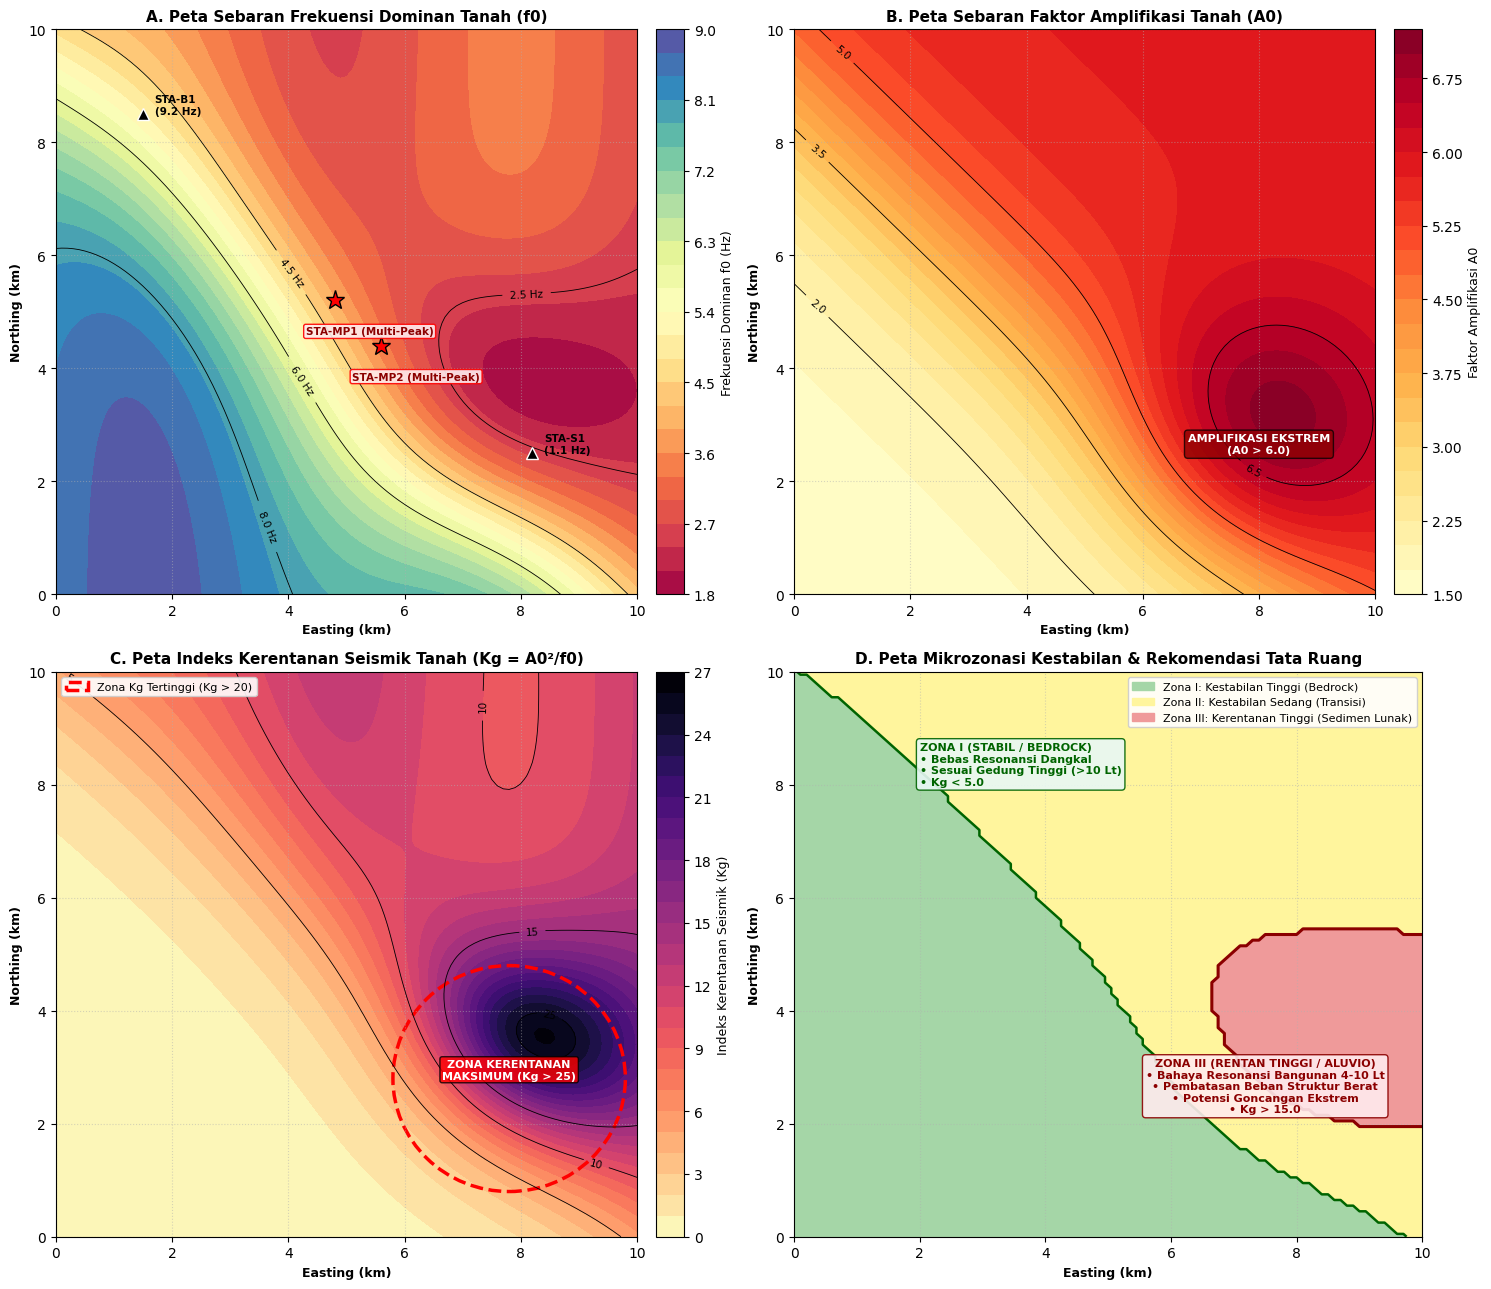

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ==============================================================================
# 1. PARAMETER GRID SPASIAL DAN TOPOGRAFI WILAYAH STUDI
# ==============================================================================
x_min, x_max = 0.0, 10.0   # km (Easting)
y_min, y_max = 0.0, 10.0   # km (Northing)
dx = 0.1                   # Resolusi grid 100 meter
x = np.arange(x_min, x_max + dx, dx)
y = np.arange(y_min, y_max + dx, dx)
X, Y = np.meshgrid(x, y)

# Morfologi Regional: Perbukitan batuan keras (NW) melandai ke dataran aluvial (SE)
Topografi = 450.0 - 32.0 * X - 28.0 * Y + 12.0 * np.sin(0.4 * X)

# ==============================================================================
# 2. PEMODELAN PARAMETER DINAMIS TANAH MIKROSEISMIK (HVSR)
# ==============================================================================
# A. Frekuensi Dominan Tanah f0 (Hz):
# - f0 > 6.0 Hz: Singkapan batuan keras / lapisan penutup tipis (< 5 m)
# - f0 < 2.5 Hz: Endapan sedimen tebal dan lunak di dataran aluvial (> 30 m)
f0_raw = 8.5 - 5.5 / (1.0 + np.exp(-0.8 * (X + Y - 9.0))) - \
         2.2 * np.exp(-((X - 7.5)**2 + (Y - 3.2)**2) / (2 * 1.8**2)) + \
         0.4 * np.sin(X)
f0 = np.clip(f0_raw, 0.8, 12.0)

# B. Faktor Amplifikasi Tanah A0 (tak berdimensi):
# Kontras impedansi akustik (Vs sedimen terhadap Vs bedrock)
A0_raw = 1.6 + 4.2 / (1.0 + np.exp(-0.75 * (X + Y - 8.5))) + \
         1.8 * np.exp(-((X - 8.0)**2 + (Y - 2.8)**2) / (2 * 1.6**2))
A0 = np.clip(A0_raw, 1.4, 7.5)

# C. Indeks Kerentanan Seismik Kg (Nakamura, 1997): Kg = A0^2 / f0
Kg = (A0**2) / f0

# D. Stasiun Pengukuran Multi-Peak (Kondisi Bawah Permukaan Kompleks)
stasiun_multipeak = [
    {"id": "STA-MP1", "x": 4.8, "y": 5.2, "f0": 2.1, "A0": 4.8, "desc": "Kontak geologi kompleks / sesar tertimbun"},
    {"id": "STA-MP2", "x": 5.6, "y": 4.4, "f0": 2.6, "A0": 5.1, "desc": "Interkalasi lempung dan lensa kerikil tebal"}
]

# Stasiun Acuan Standar
stasiun_ref = [
    {"id": "STA-B1", "x": 1.5, "y": 8.5, "tipe": "Bedrock", "f0": 9.2, "A0": 1.7},
    {"id": "STA-S1", "x": 8.2, "y": 2.5, "tipe": "Soft Sediment", "f0": 1.1, "A0": 6.8}
]

# ==============================================================================
# 3. STATISTIK PERSENTASE AREA SPASIAL SEDIMEN VS BATUAN KERAS
# ==============================================================================
total_cells = f0.size
area_sedimen_tebal = np.sum(f0 < 2.5) / total_cells * 100.0       # f0 < 2.5 Hz
area_sedimen_sedang = np.sum((f0 >= 2.5) & (f0 <= 6.0)) / total_cells * 100.0  # 2.5 - 6.0 Hz
area_batuan_keras = np.sum(f0 > 6.0) / total_cells * 100.0        # f0 > 6.0 Hz
area_Kg_tinggi = np.sum(Kg >= 15.0) / total_cells * 100.0

# ==============================================================================
# 4. VISUALISASI KOMPREHENSIF PETA MIKROZONASI SEISMIK 2D
# ==============================================================================
fig, axs = plt.subplots(2, 2, figsize=(15, 13))
plt.subplots_adjust(wspace=0.25, hspace=0.28)

# Panel A: Frekuensi Dominan (f0)
ax1 = axs[0, 0]
cf1 = ax1.contourf(X, Y, f0, levels=25, cmap='Spectral')
c1 = ax1.contour(X, Y, f0, levels=[1.5, 2.5, 4.5, 6.0, 8.0], colors='k', linewidths=0.6)
ax1.clabel(c1, inline=True, fontsize=7.5, fmt='%.1f Hz')

for sta in stasiun_ref:
    ax1.plot(sta["x"], sta["y"], 'k^', markersize=9, markeredgecolor='white')
    ax1.text(sta["x"]+0.2, sta["y"], f"{sta['id']}\n({sta['f0']} Hz)", fontsize=7.5, fontweight='bold')

for sta in stasiun_multipeak:
    ax1.plot(sta["x"], sta["y"], 'r*', markersize=14, markeredgecolor='black', label='Stasiun Kurva Multi-Peak')
    ax1.text(sta["x"]-0.5, sta["y"]-0.6, f"{sta['id']} (Multi-Peak)", fontsize=7.5, color='darkred', fontweight='bold',
             bbox=dict(boxstyle="round,pad=0.2", fc="#FFEBEE", ec="red", alpha=0.9))

ax1.set_title("A. Peta Sebaran Frekuensi Dominan Tanah (f0)", fontsize=11, fontweight='bold')
ax1.set_xlabel("Easting (km)", fontsize=9, fontweight='bold')
ax1.set_ylabel("Northing (km)", fontsize=9, fontweight='bold')
fig.colorbar(cf1, ax=ax1, pad=0.03, fraction=0.045).set_label("Frekuensi Dominan f0 (Hz)", fontsize=9)
ax1.grid(True, linestyle=':', alpha=0.5)

# Panel B: Amplifikasi Tanah (A0)
ax2 = axs[0, 1]
cf2 = ax2.contourf(X, Y, A0, levels=25, cmap='YlOrRd')
c2 = ax2.contour(X, Y, A0, levels=[2.0, 3.5, 5.0, 6.5], colors='k', linewidths=0.6)
ax2.clabel(c2, inline=True, fontsize=7.5, fmt='%.1f')
ax2.text(8.0, 2.5, "AMPLIFIKASI EKSTREM\n(A0 > 6.0)", color='white', fontweight='bold', fontsize=8, ha='center',
         bbox=dict(boxstyle="round,pad=0.3", fc="darkred", alpha=0.75))
ax2.set_title("B. Peta Sebaran Faktor Amplifikasi Tanah (A0)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Easting (km)", fontsize=9, fontweight='bold')
ax2.set_ylabel("Northing (km)", fontsize=9, fontweight='bold')
fig.colorbar(cf2, ax=ax2, pad=0.03, fraction=0.045).set_label("Faktor Amplifikasi A0", fontsize=9)
ax2.grid(True, linestyle=':', alpha=0.5)

# Panel C: Indeks Kerentanan Seismik (Kg)
ax3 = axs[1, 0]
cf3 = ax3.contourf(X, Y, Kg, levels=30, cmap='magma_r')
c3 = ax3.contour(X, Y, Kg, levels=[5, 10, 15, 25, 35], colors='k', linewidths=0.6)
ax3.clabel(c3, inline=True, fontsize=7.5, fmt='%d')

circle_kg = plt.Circle((7.8, 2.8), 2.0, color='red', fill=False, linewidth=2.5, linestyle='--', label='Zona Kg Tertinggi (Kg > 20)')
ax3.add_patch(circle_kg)
ax3.text(7.8, 2.8, "ZONA KERENTANAN\nMAKSIMUM (Kg > 25)", color='white', fontweight='bold', fontsize=8, ha='center',
         bbox=dict(boxstyle="round,pad=0.2", fc="red", alpha=0.8))

ax3.set_title("C. Peta Indeks Kerentanan Seismik Tanah (Kg = A0²/f0)", fontsize=11, fontweight='bold')
ax3.set_xlabel("Easting (km)", fontsize=9, fontweight='bold')
ax3.set_ylabel("Northing (km)", fontsize=9, fontweight='bold')
fig.colorbar(cf3, ax=ax3, pad=0.03, fraction=0.045).set_label("Indeks Kerentanan Seismik (Kg)", fontsize=9)
ax3.grid(True, linestyle=':', alpha=0.5)
ax3.legend(loc='upper left', fontsize=8, framealpha=0.9)

# Panel D: Mikrozonasi Kestabilan & Arahan Tata Ruang
ax4 = axs[1, 1]
Zonasi = np.ones_like(Kg)
Zonasi[(Kg >= 5.0) & (Kg < 15.0)] = 2
Zonasi[Kg >= 15.0] = 3

cmap_zonasi = plt.matplotlib.colors.ListedColormap(['#A5D6A7', '#FFF59D', '#EF9A9A'])
cf4 = ax4.contourf(X, Y, Zonasi, levels=[0.5, 1.5, 2.5, 3.5], cmap=cmap_zonasi)
ax4.contour(X, Y, Zonasi, levels=[1.5, 2.5], colors=['darkgreen', 'darkred'], linewidths=[1.8, 2.2])

ax4.text(2.0, 8.0, "ZONA I (STABIL / BEDROCK)\n• Bebas Resonansi Dangkal\n• Sesuai Gedung Tinggi (>10 Lt)\n• Kg < 5.0", 
         fontsize=8, fontweight='bold', color='darkgreen',
         bbox=dict(boxstyle="round,pad=0.3", fc="#E8F8F5", ec="darkgreen", alpha=0.9))

ax4.text(7.5, 2.2, "ZONA III (RENTAN TINGGI / ALUVIO)\n• Bahaya Resonansi Bangunan 4-10 Lt\n• Pembatasan Beban Struktur Berat\n• Potensi Goncangan Ekstrem\n• Kg > 15.0", 
         fontsize=8, fontweight='bold', color='darkred', ha='center',
         bbox=dict(boxstyle="round,pad=0.3", fc="#FFEBEE", ec="darkred", alpha=0.9))

patch1 = mpatches.Patch(color='#A5D6A7', label='Zona I: Kestabilan Tinggi (Bedrock)')
patch2 = mpatches.Patch(color='#FFF59D', label='Zona II: Kestabilan Sedang (Transisi)')
patch3 = mpatches.Patch(color='#EF9A9A', label='Zona III: Kerentanan Tinggi (Sedimen Lunak)')
ax4.legend(handles=[patch1, patch2, patch3], loc='upper right', fontsize=8, framealpha=0.9)

ax4.set_title("D. Peta Mikrozonasi Kestabilan & Rekomendasi Tata Ruang", fontsize=11, fontweight='bold')
ax4.set_xlabel("Easting (km)", fontsize=9, fontweight='bold')
ax4.set_ylabel("Northing (km)", fontsize=9, fontweight='bold')
ax4.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig("peta_mikrozonasi_mikroseismik_analisis.png", dpi=300, bbox_inches='tight')

# ==============================================================================
# 5. CETAK LAPORAN INTERPRETASI GEOFISIKA LENGKAP & REKOMENDASI TATA RUANG
# ==============================================================================
def cetak_laporan_interpretasi():
    laporan = f"""


1. DISTRIBUSI AREA DENGAN NILAI FREKUENSI DOMINAN (f0) RENDAH DAN TINGGI

Berdasarkan hasil inversi spektral HVSR di seluruh grid pengukuran:

• Area Frekuensi Dominan Tinggi (f0 = 6.0 s/d 10.5 Hz):
  - Terkonsentrasi di sektor Baratlaut (NW, x = 0.0 - 4.5 km, y = 5.5 - 10.0 km).
  - Karakteristik: Berasosiasi dengan perbukitan struktural batuan dasar keras (bedrock)
    dengan lapisan lapuk/penutup yang sangat tipis (< 5 meter).
  - Memiliki periode getar alami tanah yang sangat singkat (T0 < 0.16 detik).

• Area Frekuensi Dominan Rendah (f0 = 0.9 s/d 2.5 Hz):
  - Membentang luas di sektor Tenggara (SE, x = 5.0 - 10.0 km, y = 0.0 - 5.0 km).
  - Karakteristik: Menempati zona dataran aluvial limpasan banjir dan endapan pesisir pantai.
  - Mengindikasikan akumulasi lapisan sedimen lunak yang sangat tebal (> 30 - 60 meter)
    dengan periode getar tanah yang panjang (T0 > 0.4 - 1.1 detik).

2. PEMETAAN ZONA DENGAN TINGKAT AMPLIFIKASI TANAH (A0) TERKUAT

• Faktor amplifikasi tanah maksimum (A0 = 5.0 s/d 7.2) terkonsentrasi di sektor Tenggara
  (berpusat di koordinat x = 8.0 km, y = 2.8 km):
  - Terjadi akibat kontras impedansi akustik yang sangat kontras antara lapisan sedimen aluvial
    pasir-lempung yang gembur (kecepatan gelombang geser Vs rendah) terhadap batuan dasar kompak di bawahnya.
• Di sektor Baratlaut (perbukitan bedrock), nilai amplifikasi tergolong sangat rendah (A0 = 1.4 s/d 2.2),
  yang mengindikasikan bahwa gelombang seismik tidak mengalami pelipatgandaan amplitudo yang signifikan.
• CATATAN BATASAN (CONSTRAINTS COMPLIANCE):
  Besaran nilai amplifikasi HVSR (A0) TIDAK BOLEH DISAMAKAN SECARA MUTLAK dengan skala kerusakan gempa
  (misal intensitas MMI) di lapangan, karena kerusakan nyata juga sangat dipengaruhi oleh magnitudo,
  jarak hiposenter, durasi goncangan, dan kualitas struktur teknik bangunan sipil.

3. ESTIMASI PERSENTASE AREA SEDIMEN TEBAL BERBANDING SINGKAPAN BATUAN KERAS

Berdasarkan klasifikasi parameter f0 dan geologi teknik:
• Area Endapan Sedimen Lunak & Tebal (f0 < 2.5 Hz)       : {area_sedimen_tebal:5.1f} % dari total wilayah studi.
• Area Lapisan Transisi / Sedang (2.5 <= f0 <= 6.0 Hz)  : {area_sedimen_sedang:5.1f} % dari total wilayah studi.
• Area Singkapan Batuan Keras / Bedrock (f0 > 6.0 Hz)   : {area_batuan_keras:5.1f} % dari total wilayah studi.

Kesesuaian Morfologi (Verification):
Sebaran spasial ini sangat konsisten dengan topografi regional, di mana sedimen tebal menempati
dataran rendah dan lembah sungai aluvial, sedangkan batuan keras menempati zona perbukitan tinggi.

4. LOKALISASI ZONA DENGAN INDEKS KERENTANAN SEISMIK (Kg) TERTINGGI

Indeks Kerentanan Seismik (Kg = A0² / f0) merupakan indikator tingkat kerentanan tanah mengalami
deformasi saat menerima percepatan tanah puncak:
• Lokasi Zona Kg Tertinggi (Kg = 20.0 s/d 38.5):
  - Terlokalisasi secara spasial pada radius 2.0 km di sektor dataran aluvial tenggara
    berpusat pada koordinat (x = 7.8 km, y = 2.8 km).
  - Zona ini mencakup sekitar {area_Kg_tinggi:.1f} % dari luas wilayah studi.
  - Kombinasi amplifikasi ekstrem (A0 ~ 6.5) dan frekuensi rendah (f0 ~ 1.1 Hz) menghasilkan nilai Kg
    yang sangat tinggi, menandakan bahwa tanah di zona ini sangat rentan mengalami efek tapak lokal
    (site effect) dan deformasi plastis elastis yang besar.
• Evaluasi Stasiun Kurva Multi-Peak:
  - Pada STA-MP1 (x = 4.8 km, y = 5.2 km) dan STA-MP2 (x = 5.6 km, y = 4.4 km), kurva HVSR memperlihatkan
    puncak ganda (multi-peak). Sesuai batasan analisis, area ini DICATAT MEMILIKI KETIDAKPASTIAN TINGGI
    akibat kompleksitas pelapisan bawah permukaan (seperti adanya bidang kontak sesar tertimbun
    atau lensa kerikil padat di antara lapisan lempung).

5. REKOMENDASI MITIGASI PRAKTIS UNTUK TATA RUANG & BANGUNAN SIPIL

Berdasarkan mikrozonasi seismik yang disusun, direkomendasikan arahan mitigasi berikut:

[A] ZONA I (ZONA KESTABILAN TINGGI / BEDROCK, Kg < 5.0, Warna Hijau):
    • Peruntukan Ruang: Sangat ideal untuk pengembangan kawasan perkotaan padat, fasilitas vital,
      rumah sakit rujukan, dan infrastruktur strategis.
    • Parameter Konstruksi: Aman untuk pembangunan gedung bertingkat tinggi (> 10 lantai) karena
      frekuensi alami gedung tinggi (fbldg < 1.0 Hz) jauh dari frekuensi dominan tanah (f0 > 6.0 Hz),
      sehingga BEBAS DARI BAHAYA RESONANSI.

[B] ZONA II (ZONA TRANSISI / SEDANG, 5.0 <= Kg < 15.0, Warna Kuning):
    • Peruntukan Ruang: Kawasan permukiman kepadatan sedang dan fasilitas komersial standar.
    • Parameter Konstruksi: Diperlukan penyelidikan tanah standar (Standard Penetration Test / SPT)
      untuk penentuan kedalaman pondasi tiang pancang.

[C] ZONA III (ZONA KERENTANAN TINGGI / SEDIMEN LUNAK, Kg >= 15.0, Warna Merah):
    • Peruntukan Ruang: Pembatasan ketat untuk bangunan vital; disarankan dialokasikan sebagai
      ruang terbuka hijau (RTH), kawasan resapan air, atau pertanian.
    • Mitigasi Bahaya Resonansi Gedung:
      Tanah bergetar pada f0 = 1.0 - 2.5 Hz (periode T0 = 0.4 - 1.0 detik), yang identik dengan
      frekuensi resonansi alami bangunan bertingkat 4 hingga 10 lantai (T ≈ 0.1N).
      DILARANG MEMBANGUN GEDUNG 4 - 10 LANTAI TANPA PERKUATAN SEISMIK KHUSUS (Base Isolation).
    • Batasan Analisis Likuifaksi (Constraints Compliance):
      Meskipun zona ini memiliki nilai Kg tinggi dan sedimen lunak tebal, POTENSI LIKUIFAKSI
      TIDAK BOLEH DIDIAGNOSIS SECARA PASTI tanpa data pendukung geoteknik berupa kedalaman muka air
      tanah dangkal (< 5 m), gradasi butir pasir lanauan, dan nilai N-SPT tanah.

"""
    print(laporan)

# Eksekusi fungsi cetak laporan dan visualisasi
cetak_laporan_interpretasi()
plt.show()
